# <a id="ust" name="ust"></a>Sıfırdan DeepSeek — Verimli LLM Mimarisi (12 Ders, Türkçe)
### Serinin tüm kodu, tek defterde

DeepSeek V3'ü verimli kılan beş yeniliği sıfırdan yazıyoruz: Multi-Head Latent Attention,
RoPE, Mixture of Experts, Multi-Token Prediction ve FP8 quantization. Serinin sonunda ilk
dördü tek modelde birleşiyor — **mini-DeepSeek** — ve 1. serinin mini-GPT'siyle aynı korpusta
yarışıyor; FP8 ise T4'te donanımı olmadığı için simülasyonla gösterilir.

**Ön koşul:** bu defter, *Sıfırdan ChatGPT* serisinin (16 ders) üstüne kurulur. Ders 1'in kod
kısmı **temel katmandır**: o serinin bitmiş GPT'si final hâliyle yüklenir, yeniden ANLATILMAZ —
her hücrenin başındaki gönderme hangi derste yazıldığını söyler. Sonraki her ders bu temelin
bir parçasını söker ve DeepSeek'in parçasını takar.

**Her ders iki aşamalıdır.** Kavram anlatım haritasında sezgiyle kurulur (`map.excalidraw`),
sonra bu defter açılır: kod burada çalışır, sayılar burada çıkar, çıktı burada okunur.

Defter **kendine yeter:** eksik kütüphaneyi kurar, korpusu bulur (yanında yoksa serinin
deposundan indirir), GPU varsa GPU'da koşar. Model ağırlığı indirmez: her model burada,
sıfırdan eğitilir. Yerelde, Colab'da ve Kaggle'da aynı biçimde çalışır.

| | |
| --- | --- |
| **Nasıl kullanılır** | Yukarıdan aşağı çalıştır. Bir derse atlamak için kurulumun altındaki içindekilerden tıkla. |
| **Kod kümülatiftir** | Her ders Ders 1'in sınıflarından türer ve yalnız bir parçayı değiştirir: MLA dersleri attention'ı, MoE dersleri feed forward'u. Dersin başındaki tek satır, önceki derslerden hangi parçaların kullanıldığını söyler. Ders başına ayrı defter yoktur; `import` gerekmez. |
| **◆ işareti** | Kodda `◆ YENİ` / `◆ DEĞİŞTİ` / `◆ SİLİNDİ`: 1. serinin koduna ya da dersin türediği sınıfa göre eklenen, değişen ya da çıkan satır. |
| **İnternet** | Açık olsun: GPT-2 tokenizer'ının sözlük dosyaları (~1.5 MB) ilk çalıştırmada iner; defteri tek başına açtıysan korpus da (23 KB) iner. |
| **Süre** | Kaggle 2×T4'te baştan sona ~3 dk. GPU'suz da çalışır ama CPU'da saatler sürer. |
| **Renkli kutular** | 🟩 anlatım · 🟦 çıktının okunması · 🟨 yapılacak iş · 🟥 tuzak |
| **Anlatım haritası** | `part-<n>-<ad>/<NN>-<ad>/map.excalidraw` |

**Nereden açıyorsan:**

| | |
| --- | --- |
| **Kaggle** | Defteri yükle, sağ panelden **GPU T4 ×2** ve **Internet** anahtarlarını aç (ikisi de kapalı gelir), Run All. Korpus kendiliğinden iner. |
| **Colab** | Defteri aç, **Runtime > Change runtime type > GPU**, Run All. Korpus kendiliğinden iner. |
| **Yerel** | Depoyu klonla, defteri depo kökünde aç. `_data/` yanında olduğu için indirme bile olmaz. |

**Serinin sonunda elinde ne olacak:** KV cache'li üretim · kendi yazdığın MQA/GQA ·
Multi-Head Latent Attention (decoupled RoPE ile, V3'ün cache tasarımı) · kendi yazdığın RoPE ·
DeepSeekMoE (shared expert + aux-loss-free denge) · Multi-Token Prediction ·
FP8 simülasyonu · ve MLA, RoPE, DeepSeekMoE ile MTP'nin birleştiği, kendi eğittiğin mini-DeepSeek.

<hr id="kurulum" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Kurulum

Bu iki hücre bir kez çalışır: ortamı hazırlar ve veriyi yerine koyar. Sonrasında hiçbir ders kurulumla uğraşmaz.

In [1]:
# --- 1) Eksik kütüphaneleri kur (varsa dokunma) --------------------------------
import importlib.metadata, importlib.util, subprocess, sys

def ensure_package(package, module=None):
    """Modül yoksa kurar. Colab/Kaggle'da çoğu zaten hazırdır; o zaman hiçbir şey yapmaz."""
    if importlib.util.find_spec(module or package) is None:
        print(f"kuruluyor: {package}")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

for _pkg, _mod in [("torch", "torch"), ("tiktoken", "tiktoken"), ("numpy", "numpy"),
                   ("matplotlib", "matplotlib")]:
    ensure_package(_pkg, _mod)

# --- 2) Ortak içe aktarmalar ---------------------------------------------------
import json, math, os, re, time, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# --- 3) Cihaz: GPU varsa GPU, yoksa CPU ---------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(123)          # sabit tohum: her koşuda aynı sayılar çıkar

print("torch     :", torch.__version__)
print("tiktoken  :", importlib.metadata.version("tiktoken"))
print("cihaz     :", device, f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
print("çekirdek  :", os.cpu_count())

# --- 4) GPT-2 tokenizer'ı: sözlük dosyaları ilk kullanımda iner (~1.5 MB) ------
# tiktoken dosyaları OpenAI'ın sunucusundan bir kez indirip önbelleğe alır. İnternet
# kapalıysa hata burada, anlaşılır bir mesajla çıksın — Ders 1'in ortasında değil.
try:
    _enc = tiktoken.get_encoding("gpt2")
except Exception as err:
    raise RuntimeError(chr(10).join([
        f"GPT-2 tokenizer dosyaları indirilemedi ({type(err).__name__}).",
        "İnternet kapalı olabilir:",
        "  Kaggle : sağ panel > Internet anahtarını aç, hücreyi yeniden çalıştır",
        "  Colab  : internet varsayılan açıktır; bağlantıyı denetle",
        "  Yerel  : bir kez internetle çalıştır, dosyalar önbellekte kalır",
    ])) from None
print("tokenizer :", f"gpt2 · {_enc.n_vocab} token")

# --- 5) Ders künyesi -----------------------------------------------------------
_T0 = time.time()

def lesson(no, title):
    """Her dersin ilk hücresi: hangi derste olduğumuzu ve koşunun kaçıncı dakikasında
    olduğumuzu yazar. İçindekilerdeki ders bağları doğrudan bu hücreye iner."""
    print(f"Ders {no:02d} · {title}   ·   {(time.time() - _T0) / 60:.1f} dk")

torch     : 2.10.0+cu128
tiktoken  : 0.12.0
cihaz     : cuda (Tesla T4)
çekirdek  : 4


tokenizer : gpt2 · 50257 token


<div class="alert alert-block alert-info">

İkinci hücre **veri çözücüdür.** Serinin tek veri dosyası — ön eğitim korpusu — üç yerde sırayla aranır: defterin yanı başında (`_data/`), Kaggle'a eklenmiş girdilerde, ve son çare olarak serinin deposundan indirilir. **Depoyu klonladıysan hiçbiri gerekmez, dosya zaten yanında.** Defteri tek başına açtıysan üçüncü adım devreye girer ve internet ister.

Korpus 1. serininkiyle (Sıfırdan ChatGPT) AYNI dosyadır: kapanış deneyindeki "aynı korpus, aynı bütçe" karşılaştırması buna dayanır. Bu yüzden serinin deposu açılamazsa 1. serinin deposu yedek kaynaktır. Bundan sonra hiçbir ders dosya yolu yazmaz: `data_path('how-words-work.txt')` denir ve doğru yol gelir.

</div>

In [2]:
# --- Veri çözücü ---------------------------------------------------------------

DATA_DIR = Path("_data")
DATA_DIR.mkdir(exist_ok=True)

# Serinin tek veri dosyası ön eğitim korpusudur ve 1. serininkiyle (Sıfırdan ChatGPT)
# AYNI dosyadır: kapanış deneyinin "aynı korpus" iddiası buna dayanır. Sıra: yerelde
# ara → Kaggle'a eklenen girdilerde ara → serinin deposundan indir → 1. serinin deposu.
SOURCES = ["how-words-work.txt"]
SEARCH_DIRS = ["_data", ".", "../_data", "../../_data"]
KAGGLE_INPUT_DIR = Path("/kaggle/input")
REPO_DATA_URLS = [
    "https://raw.githubusercontent.com/celiktepesahin/deepseek-from-scratch-tr/main/_data",   # bu serinin deposu
    "https://raw.githubusercontent.com/celiktepesahin/chatgpt-from-scratch-tr/main/_data",   # 1. seri, aynı korpus
]


def data_path(name):
    """Dosyanın yolunu döndürür. Bulamazsa ne yapılacağını söyleyerek durur."""
    target = DATA_DIR / name
    if target.exists():
        return target

    for folder in SEARCH_DIRS:                       # 1) defterin yanı başı
        candidate = Path(folder) / name
        if candidate.exists() and candidate.resolve() != target.resolve():
            target.write_bytes(candidate.read_bytes())
            return target

    if KAGGLE_INPUT_DIR.is_dir():                   # 2) Kaggle: + Add Input ile eklenen ne varsa
        for candidate in KAGGLE_INPUT_DIR.glob(f"*/**/{name}"):
            target.write_bytes(candidate.read_bytes())
            print(f"     girdiden alındı: {candidate}")
            return target

    err = None
    for url in REPO_DATA_URLS:                      # 3) serinin deposundan indir
        try:
            with urllib.request.urlopen(f"{url}/{name}", timeout=60) as r:
                target.write_bytes(r.read())
            print(f"     indirildi: {url}/{name}")
            return target
        except Exception as e:
            err = e
    hint = [
        f"{name} ne yerelde bulundu ne de indirilebildi ({type(err).__name__}).",
        "İnternet kapalıysa önce onu aç (Kaggle: sağ panel > Internet).",
        "Elle koymak istersen dosya serinin deposunda _data/ altındadır:",
        "  Kaggle : sağ panel > + Add Input > Upload > dosyayı seç, hücreyi yeniden çalıştır",
        "  Colab  : soldaki klasör simgesi > yükle (dosya /content'e düşer, yeter)",
        "  Yerel  : defterin yanına _data/ klasörü aç, dosyayı içine koy",
    ]
    raise FileNotFoundError(chr(10).join(hint)) from None


for _name in SOURCES:
    print(" ->", data_path(_name))

 -> _data/how-words-work.txt


<hr id="icindekiler" style="border:0;margin:0;scroll-margin-top:6rem">

## İçindekiler

Ders adına tıkla, derse gider. Kaggle, Colab ve GitHub'da adın yanındaki **#** işaretini kullan.


**<a href="vscode-notebook-cell:?execution_count=3&line=1">BÖLÜM 1 · Köprü</a>** <sup><a href="#bolum-1" title="Kaggle / Colab / GitHub bağı">#</a></sup>

- <a href="vscode-notebook-cell:?execution_count=3&line=1">Ders 01 · GPT'den DeepSeek'e: V3, R1 ve Beş Yenilik</a> <sup><a href="#ders-01" title="Kaggle / Colab / GitHub bağı">#</a></sup>

**<a href="vscode-notebook-cell:?execution_count=15&line=1">BÖLÜM 2 · Attention'ın Gelişimi</a>** <sup><a href="#bolum-2" title="Kaggle / Colab / GitHub bağı">#</a></sup>

- <a href="vscode-notebook-cell:?execution_count=15&line=1">Ders 02 · KV Cache: Hızlanan Çıkarım, Şişen Bellek</a> <sup><a href="#ders-02" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=21&line=1">Ders 03 · MQA ve GQA: Kafaları Paylaştırmak</a> <sup><a href="#ders-03" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=24&line=1">Ders 04 · Multi-Head Latent Attention: Sıkıştırılmış Bellek</a> <sup><a href="#ders-04" title="Kaggle / Colab / GitHub bağı">#</a></sup>

**<a href="vscode-notebook-cell:?execution_count=27&line=1">BÖLÜM 3 · RoPE</a>** <sup><a href="#bolum-3" title="Kaggle / Colab / GitHub bağı">#</a></sup>

- <a href="vscode-notebook-cell:?execution_count=27&line=1">Ders 05 · RoPE'ye Giden Yol: Konumu Döndürerek Kodlamak</a> <sup><a href="#ders-05" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=29&line=1">Ders 06 · MLA + RoPE: DeepSeek'in Gerçek Uygulaması</a> <sup><a href="#ders-06" title="Kaggle / Colab / GitHub bağı">#</a></sup>

**<a href="vscode-notebook-cell:?execution_count=33&line=1">BÖLÜM 4 · Mixture of Experts</a>** <sup><a href="#bolum-4" title="Kaggle / Colab / GitHub bağı">#</a></sup>

- <a href="vscode-notebook-cell:?execution_count=33&line=1">Ders 07 · Mixture of Experts: Router ve Seyreklik</a> <sup><a href="#ders-07" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=37&line=1">Ders 08 · Load Balancing: Uzmanları Dengede Tutmak</a> <sup><a href="#ders-08" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=43&line=1">Ders 09 · DeepSeekMoE: Shared Expert ve Aux-Loss-Free Denge</a> <sup><a href="#ders-09" title="Kaggle / Colab / GitHub bağı">#</a></sup>

**<a href="vscode-notebook-cell:?execution_count=46&line=1">BÖLÜM 5 · Eğitim Verimliliği ve Kapanış</a>** <sup><a href="#bolum-5" title="Kaggle / Colab / GitHub bağı">#</a></sup>

- <a href="vscode-notebook-cell:?execution_count=46&line=1">Ders 10 · Multi-Token Prediction: Bir Adımda Fazlası</a> <sup><a href="#ders-10" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=50&line=1">Ders 11 · Quantization ve FP8: Karma Hassasiyet</a> <sup><a href="#ders-11" title="Kaggle / Colab / GitHub bağı">#</a></sup>
- <a href="vscode-notebook-cell:?execution_count=53&line=1">Ders 12 · Kapanış: mini-DeepSeek'i Birleştir ve Koştur</a> <sup><a href="#ders-12" title="Kaggle / Colab / GitHub bağı">#</a></sup>

<hr id="bolum-1" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

# BÖLÜM 1 · KÖPRÜ

<hr id="ders-01" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 01 · GPT'den DeepSeek'e: V3, R1 ve Beş Yenilik

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="vscode-notebook-cell:?execution_count=15&line=1">Ders 02</a> <a href="#ders-02">→</a></sub>

In [3]:
lesson(1, "GPT'den DeepSeek'e: V3, R1 ve Beş Yenilik")

Ders 01 · GPT'den DeepSeek'e: V3, R1 ve Beş Yenilik   ·   0.0 dk


**Problem:** Sıfırdan ChatGPT'nin GPT'si çalışıyor ama pahalı — DeepSeek-V3 aynı işi neyi değiştirerek daha ucuza yapıyor? Ders önce bu soruyu cevaplar, ardından serinin her dersinin parça takacağı temeli kurup koşturur.

### Neden DeepSeek: üç fatura, beş yenilik

<div class="alert alert-block alert-success">

Bu konunun kodu yok: kavram anlatım haritasında kurulur, aşağıdaki kutular onun özetidir.

</div>

#### V3 ve R1

<div class="alert alert-block alert-success">

**DeepSeek-V3** modelin kendisidir: mimarisi ve ön eğitimi; verimlilik yeniliklerinin hepsi burada. **DeepSeek-R1** aynı gövdeyi akıl yürütmeye ayrıca eğiten tariftir; bu seri V3'ü yazar.

</div>

#### Fatura 1 · Inference (çıkarım)

<div class="alert alert-block alert-success">

Cache'siz üretimde her yeni token bütün geçmişi yeniden işler: 5 token için 1 + 2 + 3 + 4 + 5 = 15 konum, 100 token'da işin 50 katı. Bölüm 2 bu hesabı önce saklar (KV Cache), sonra saklananı küçültür (MQA, GQA, MLA).

</div>

#### Fatura 2 · Kapasite

<div class="alert alert-block alert-success">

Dense feed forward'da her token bütün parametrelerden geçer; Mixture of Experts'te Router her token için birkaç uzman seçer. DeepSeek-V3'ün 671 milyar parametresinden token başına 37 milyarı çalışır (Bölüm 4).

</div>

#### Fatura 3 · Eğitim

<div class="alert alert-block alert-success">

Her konum yalnız bir sonraki token'ı tahmin eder ve her sayı 32 bit taşır. Multi-Token Prediction aynı adımdan ikinci bir tahmin alır (Ders 10); FP8 sayıların çoğunu 8 bite indirir, T4'te simülasyonla (Ders 11).

</div>

#### Yol haritası

<div class="alert alert-block alert-success">

Her ders bir öncekinin açtığı sorunla başlar; sıra içindekilerdeki gibidir. Ders 12'de dört yenilik RMSNorm ve SwiGLU ile tek modelde birleşir; DualPipe ve Expert Parallelism bilerek dışarıda, çünkü çoklu GPU ister.

</div>

### Temel katman: 1. serinin bitmiş GPT'si

<div class="alert alert-block alert-success">

Bu hücreler *Sıfırdan ChatGPT*'nin bitmiş GPT'sidir: anlatılmaz, kurulur; her başlığın altındaki kutu sınıfın hangi derste yazıldığını söyler. **◆ işaretli satırlar** 1. seride yoktu: sonraki derslerin DeepSeek parçasını takacağı yuvalar.

</div>

#### Korpus ve tokenizer

<div class="alert alert-block alert-success">

Korpus iki serinin ortak dosyası, tokenizer GPT-2'nin BPE'si — *Sıfırdan ChatGPT Ders 2–3*. Aynı metin, Ders 12'de iki modelin aynı veride yarışmasının şartı.

</div>

In [4]:
# korpus: iki serinin ortak metni; yolunu kurulumdaki data_path() bulur
with open(data_path("how-words-work.txt"), "r", encoding="utf-8") as f:
    raw_text = f.read()                     # metnin tamamı, tek string

tokenizer = tiktoken.get_encoding("gpt2")   # GPT-2'nin BPE tokenizer'ı, sözlük 50 257
corpus_ids = tokenizer.encode(raw_text)     # metin -> token ID listesi

print("karakter   :", len(raw_text))        # metin kaç karakter
print("BPE token  :", len(corpus_ids))      # aynı metin kaç token

karakter   : 23784
BPE token  : 5542


#### Veri hattı: Sliding Window (kayan pencere)

<div class="alert alert-block alert-success">

Kayan pencere metni (girdi, hedef) çiftlerine keser; hedef, girdinin bir token sağıdır — *Sıfırdan ChatGPT Ders 3*.

</div>

In [5]:
class GPTDataset(Dataset):
    """Metni kayan pencereyle (girdi, hedef) çiftlerine keser. Hedef = girdi + 1 kayma."""

    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []                                       # girdi pencereleri
        self.target_ids = []                                      # hedef pencereleri
        # metin -> token ID listesi; <|endoftext|> tek token sayılır
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        for i in range(0, len(token_ids) - max_length, stride):   # pencere başı stride kadar kayar
            input_chunk = token_ids[i:i + max_length]             # girdi: max_length token
            target_chunk = token_ids[i + 1: i + max_length + 1]   # hedef: aynı boy, 1 token sağda
            self.input_ids.append(torch.tensor(input_chunk))      # tensör: (max_length,)
            self.target_ids.append(torch.tensor(target_chunk))    # tensör: (max_length,)

    def __len__(self):
        return len(self.input_ids)                                # pencere sayısı

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]          # idx. pencere: (girdi, hedef)


def create_dataloader(txt, batch_size=4, max_length=256, stride=128,
                      shuffle=True, drop_last=True, num_workers=0):
    dataset = GPTDataset(txt, tokenizer, max_length, stride)      # pencereler; tokenizer korpus hücresinden
    # pencereleri yığınlara topla; shuffle: her Epoch'ta karıştır, drop_last: yarım son yığını at
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, num_workers=num_workers)

#### Attention: üç ortak adım

<div class="alert alert-block alert-success">

Causal maskeli multi-head attention — *Sıfırdan ChatGPT Ders 5–6*. ◆ `forward`'ın üç adımı fonksiyon oldu (`split_heads`, `attention_weights`, `merge_heads`): Bölüm 2–3'ün her attention'ı bunları kullanır, yalnız Q, K ve V'yi başka kurar.

</div>

In [6]:
def split_heads(x, num_heads):                                      # ◆ YENİ: BÖL + GRUPLA adımı
    """(b, T, d) -> (b, num_heads, T, d / num_heads): son eksen kafalara bölünür."""
    b, num_tokens, d = x.shape                                      # d: bütün kafaların toplam boyu
    # (b, T, num_heads, head_dim), sonra her kafa kendi (T, head_dim) tablosuyla
    return x.view(b, num_tokens, num_heads, d // num_heads).transpose(1, 2)


def attention_weights(attn_scores, mask_bool, head_dim, dropout):   # ◆ YENİ: MASKE + SOFTMAX adımı
    """Skor tablosundan ağırlıklara: gelecek maskelenir, ölçekli softmax, Dropout."""
    attn_scores.masked_fill_(mask_bool, -torch.inf)                 # gelecek konumların skoru -inf
    # kök(head_dim)'e böl, softmax: her satırın toplamı 1
    attn_weights = torch.softmax(attn_scores / head_dim ** 0.5, dim=-1)
    return dropout(attn_weights)                                    # eğitimde rastgele sıfırla


def merge_heads(x):                                                 # ◆ YENİ: BİRLEŞTİR adımı
    """(b, num_heads, T, head_dim) -> (b, T, num_heads · head_dim): kafalar yan yana."""
    b, num_heads, num_tokens, head_dim = x.shape                    # dört eksenin boyu
    return x.transpose(1, 2).contiguous().view(b, num_tokens, num_heads * head_dim)


class MultiHeadAttention(nn.Module):
    """Klasik çok kafalı, causal maskeli attention (1. serinin final sınıfı)."""

    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out, num_heads'e tam bölünmeli"
        self.num_heads = num_heads                                  # kafa sayısı
        self.head_dim = d_out // num_heads                          # kafa başına boy (mini: 256 / 4 = 64)

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)        # sorgu (Q) matrisi
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)          # anahtar (K) matrisi
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)        # değer (V) matrisi
        self.out_proj = nn.Linear(d_out, d_out)                     # kafa çıktılarını karıştırır
        self.dropout = nn.Dropout(dropout)                          # attention ağırlıklarında Dropout
        # causal maske: köşegenin üstü 1 = gelecek konum; buffer: eğitilmez, modelle cihaza taşınır
        self.register_buffer("mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):                                           # ◆ DEĞİŞTİ: aynı adımlar, üç fonksiyonla
        num_tokens = x.shape[1]                                     # T: token sayısı
        keys = split_heads(self.W_key(x), self.num_heads)           # K: (b, n_head, T, head_dim)
        queries = split_heads(self.W_query(x), self.num_heads)      # Q: aynı şekil
        values = split_heads(self.W_value(x), self.num_heads)       # V: aynı şekil
        attn_scores = queries @ keys.transpose(2, 3)                # SKOR: her kafada Q·Kᵀ, (b, n_head, T, T)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]      # maskenin T × T köşesi
        # maske + softmax + Dropout: (b, n_head, T, T)
        attn_weights = attention_weights(attn_scores, mask_bool, self.head_dim, self.dropout)
        # ağırlıklı toplam (b, n_head, T, head_dim) -> kafalar yan yana (b, T, d_out) -> karıştır
        return self.out_proj(merge_heads(attn_weights @ values))

#### Bloğun parçaları: LayerNorm, GELU, FeedForward

<div class="alert alert-block alert-success">

*Sıfırdan ChatGPT Ders 7*. Üçü de 1. serinin kodu; Ders 12 yuvalardan RMSNorm ve SwiGLU takar.

</div>

In [7]:
class LayerNorm(nn.Module):
    """Son ekseni ortalama 0, varyans 1'e çeker; scale ve shift öğrenilir."""

    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5                                      # sıfıra bölmeyi önler
        self.scale = nn.Parameter(torch.ones(emb_dim))       # öğrenilen ölçek, 1'den başlar
        self.shift = nn.Parameter(torch.zeros(emb_dim))      # öğrenilen kaydırma, 0'dan başlar

    def forward(self, x):                                    # x: (b, T, emb_dim)
        mean = x.mean(dim=-1, keepdim=True)                  # her token'ın ortalaması
        var = x.var(dim=-1, keepdim=True, unbiased=False)    # her token'ın varyansı (bölen n)
        # normalize et, sonra öğrenilen ölçek ve kaydırma; şekil aynı kalır
        return self.scale * (x - mean) / torch.sqrt(var + self.eps) + self.shift


class GELU(nn.Module):
    """Yumuşak eşikli aktivasyon (tanh yaklaşımı)."""

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(                    # 0.5·x·(1 + tanh(...)), her sayı ayrı
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *       # katsayı: kök(2/π)
            (x + 0.044715 * torch.pow(x, 3))))               # x + 0.044715·x³


class FeedForward(nn.Module):
    """Genişlet (4x) -> GELU -> daralt. Bloğun parametre yığını burada."""

    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(                         # üç katman, sırayla
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),   # genişlet: emb_dim -> 4 × emb_dim
            GELU(),                                          # yumuşak eşik
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),   # daralt: 4 × emb_dim -> emb_dim
        )

    def forward(self, x):
        return self.layers(x)                                # (b, T, emb_dim) -> aynı şekil

#### Transformer bloğu ve GPT modeli: üç yuva

<div class="alert alert-block alert-success">

*Sıfırdan ChatGPT Ders 8–9*. ◆ Blok parçalarını üç yuva metoduyla kurar (`make_attention`, `make_feed_forward`, `make_norm`), model dizeceği bloğu `block` parametresinden alır: sonraki dersler yalnız değişen yuvayı yeniden yazan alt sınıf yazar.

</div>

In [8]:
class TransformerBlock(nn.Module):
    """Norm -> attention -> ekle, norm -> feed forward -> ekle (pre-norm düzeni)."""

    def __init__(self, cfg):
        super().__init__()
        self.att = self.make_attention(cfg)                     # ◆ DEĞİŞTİ: attention'ı yuva metodu kurar
        self.ff = self.make_feed_forward(cfg)                   # ◆ DEĞİŞTİ: feed forward'u yuva metodu kurar
        self.norm1 = self.make_norm(cfg)                        # ◆ DEĞİŞTİ: attention öncesi norm, yuvadan
        self.norm2 = self.make_norm(cfg)                        # ◆ DEĞİŞTİ: feed forward öncesi norm, yuvadan
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])       # kısayola eklenmeden önce Dropout

    def make_attention(self, cfg):                              # ◆ YENİ: yuva 1 — Bölüm 2–3 değiştirir
        return MultiHeadAttention(                              # causal maskeli multi-head attention
            d_in=cfg["emb_dim"], d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])

    def make_feed_forward(self, cfg):                           # ◆ YENİ: yuva 2 — Bölüm 4, Ders 12 değiştirir
        return FeedForward(cfg)                                 # genişlet, GELU, daralt

    def make_norm(self, cfg):                                   # ◆ YENİ: yuva 3 — Ders 12 RMSNorm takar
        return LayerNorm(cfg["emb_dim"])                        # 1. serinin LayerNorm'u

    def forward(self, x):                                       # x: (b, T, emb_dim)
        x = x + self.drop_shortcut(self.att(self.norm1(x)))     # norm -> attention -> kısayola ekle
        return x + self.drop_shortcut(self.ff(self.norm2(x)))   # norm -> feed forward -> kısayola ekle


class GPTModel(nn.Module):
    """Token embedding + öğrenilen konum tablosu + N blok + çıkış kafası."""

    def __init__(self, cfg, block=TransformerBlock):            # ◆ YENİ: block — dizilecek blok sınıfı
        super().__init__()
        # token embedding tablosu: vocab_size satır, her satır emb_dim boy
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        # öğrenilen konum tablosu: context_length satır, her satır emb_dim boy
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])            # embedding'den sonra Dropout
        self.trf_blocks = nn.Sequential(                        # ◆ DEĞİŞTİ: n_layers tane `block`, sırayla
            *[block(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])             # son LayerNorm
        # çıkış kafası: emb_dim -> vocab_size logit, bias yok
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):                                  # in_idx: (b, T) token ID'leri
        seq_len = in_idx.shape[1]                               # T: token sayısı
        tok_embeds = self.tok_emb(in_idx)                       # (b, T) -> (b, T, emb_dim)
        # konum tablosunun ilk T satırı: (T, emb_dim)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = self.drop_emb(tok_embeds + pos_embeds)              # token + konum, sonra Dropout
        x = self.trf_blocks(x)                                  # bloklar sırayla; şekil değişmez
        return self.out_head(self.final_norm(x))                # son LayerNorm, logit: (b, T, vocab_size)

#### Loss ve Training Loop (eğitim döngüsü)

<div class="alert alert-block alert-success">

Cross-Entropy, ara ölçüm ve eğitim döngüsü — *Sıfırdan ChatGPT Ders 10*. ◆ `train_model` kaybı `loss_fn` yuvasından alır: Ders 10 buraya iki kafalı MTP kaybını takar.

</div>

In [9]:
def calc_loss_batch(input_batch, target_batch, model, device):
    # girdi ve hedef modelin cihazına
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)                                     # (b, T) -> (b, T, vocab_size)
    # Cross-Entropy: (b·T, vocab_size) logit ile (b·T,) hedef token; bütün konumların ortalaması
    return torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.0                                                # yığın kayıplarının toplamı
    # kaç yığın: verilmediyse hepsi, verildiyse yükleyicideki sayıyı aşmaz
    num_batches = len(data_loader) if num_batches is None else min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):   # yığınlar sırayla
        if i >= num_batches:                                        # istenen sayı ölçüldü
            break
        # yığının kaybı, düz sayı olarak toplama eklenir
        total_loss += calc_loss_batch(input_batch, target_batch, model, device).item()
    return total_loss / num_batches                                 # yığın başına ortalama kayıp


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()                                                    # ölçüm modu: Dropout kapalı
    with torch.no_grad():                                           # gradyan tutulmaz
        # eğitim kümesinin ilk eval_iter yığını
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        # doğrulama kümesinin ilk eval_iter yığını
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()                                                   # eğitime dön: Dropout açık
    return train_loss, val_loss                                     # iki ortalama kayıp


# log=False: ölçüm satırları basılmaz · ◆ YENİ: loss_fn — kayıp yuvası (Ders 10 MTP kaybını takar)
def train_model(model, train_loader, val_loader, optimizer, device, num_epochs,
                eval_freq, eval_iter, log=True, loss_fn=calc_loss_batch):
    """Basit ön eğitim döngüsü: her adımda geri yayılım, aralıklarla ölçüm."""
    train_losses, val_losses, track_tokens_seen = [], [], []        # ölçüm günlüğü
    tokens_seen, global_step = 0, -1                                # sayaçlar; ilk adımda global_step 0 olur
    for epoch in range(num_epochs):                                 # Epoch: eğitim kümesinin tamamı bir kez
        model.train()                                               # eğitim modu: Dropout açık
        for input_batch, target_batch in train_loader:              # her yığın bir adım
            optimizer.zero_grad()                                   # önceki adımın gradyanlarını sil
            # ◆ DEĞİŞTİ: ileri geçiş ve kayıp, loss_fn ile (varsayılanı calc_loss_batch)
            loss = loss_fn(input_batch, target_batch, model, device)
            loss.backward()                                         # geri yayılım: her ağırlığın gradyanı
            optimizer.step()                                        # ağırlıkları güncelle
            tokens_seen += input_batch.numel()                      # bu yığının token sayısı (b × T)
            global_step += 1                                        # adım sayacı
            if global_step % eval_freq == 0:                        # her eval_freq adımda bir ölçüm
                train_loss, val_loss = evaluate_model(              # iki kayıp, ilk eval_iter yığınla
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)                     # günlüğe: eğitim kaybı
                val_losses.append(val_loss)                         # doğrulama kaybı
                track_tokens_seen.append(tokens_seen)               # o ana kadar görülen token
                if log:                                             # ölçüm satırını bas
                    print(f"Tur {epoch + 1} (adım {global_step:04d}): "
                          f"eğitim {train_loss:.3f} · doğrulama {val_loss:.3f}")
    return train_losses, val_losses, track_tokens_seen              # kayıp eğrisinin üç listesi

#### Üretim: argmax

<div class="alert alert-block alert-success">

*Sıfırdan ChatGPT Ders 11*, temperature ve top-k dalları olmadan: her adımda en olası token seçilir, her koşuda aynı metin çıkar. `generate` her turda bütün diziyi modele yeniden verir — Ders 2'nin ölçeceği tekrar bu.

</div>

In [10]:
def text_to_token_ids(text, tokenizer):
    # metin -> token ID listesi; <|endoftext|> tek token sayılır
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    return torch.tensor(encoded).unsqueeze(0)                # (T,) -> (1, T): başa yığın ekseni


def token_ids_to_text(token_ids, tokenizer):
    return tokenizer.decode(token_ids.squeeze(0).tolist())   # (1, T) -> (T,) -> metin


def generate(model, idx, max_new_tokens, context_size):
    """Her turda TÜM diziyi modele verir — Ders 2'nin ölçeceği pahalılık tam burada."""
    for _ in range(max_new_tokens):                          # her adımda bir yeni token
        idx_cond = idx[:, -context_size:]                    # pencereye sığan son token'lar
        with torch.no_grad():                                # üretimde gradyan gerekmez
            logits = model(idx_cond)                         # bütün dizi yeniden: (b, T, vocab_size)
        # yalnız son konum; en olası token (argmax): (b, 1)
        idx_next = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)              # dizinin sonuna ekle: (b, T + 1)
    return idx

### Temeli koştur: mini-GPT

<div class="alert alert-block alert-success">

Serinin çalışma boyu `GPT_MINI`: *Sıfırdan ChatGPT*'nin 124M'lik yapılandırması değil, aynı mimari **deney boyunda** — her ders birkaç kısa eğitim karşılaştırması yapacak.

</div>

#### GPT_MINI: kur ve say

<div class="alert alert-block alert-success">

Hücre modeli kurar ve parametreleri parça parça sayar; `count_params` serinin sonuna kadar her tartıda kullanılır.

</div>

In [11]:
def count_params(module):                                # bir modülün toplam parametre sayısı
    return sum(p.numel() for p in module.parameters())   # her ağırlık tensörünün eleman sayısı, toplanır


GPT_MINI = {                                             # mini-GPT'nin ayarları
    "vocab_size": 50257,                                 # GPT-2 BPE sözlüğü: tokenizer'la aynı olmalı
    "context_length": 256,                               # pencere: en çok 256 token
    "emb_dim": 256,                                      # token vektörünün boyu
    "n_heads": 4,                                        # attention kafası: head_dim = 256 / 4 = 64
    "n_layers": 4,                                       # transformer bloğu sayısı
    "drop_rate": 0.1,                                    # Dropout oranı
    "qkv_bias": False,                                   # Q, K, V katmanlarında bias yok
}

torch.manual_seed(123)                                   # her koşuda aynı başlangıç ağırlıkları
model = GPTModel(GPT_MINI).to(device)                    # mini-GPT'yi kur, cihaza taşı

total_params = count_params(model)                       # toplam: bütün parametre tensörleri
# iki tablo: token embedding + konum tablosu
emb_params = model.tok_emb.weight.numel() + model.pos_emb.weight.numel()
print(f"toplam parametre    : {total_params:,}")
print(f"  embedding tablosu : {emb_params:,}")
print(f"  çıkış kafası      : {model.out_head.weight.numel():,}")
# gövde = toplam - iki tablo - çıkış kafası: blokların payı
print(f"  gövde (bloklar)   : {total_params - emb_params - model.out_head.weight.numel():,}")

toplam parametre    : 28,953,600
  embedding tablosu : 12,931,328
  çıkış kafası      : 12,865,792
  gövde (bloklar)   : 3,156,480


<div class="alert alert-block alert-info">

Parametrelerin çoğu iki sözlük tablosunda: token tablosu ve çıkış kafası, ikisi de 50 257 × 256. Gövde küçük; attention ve feed forward yenilikleri bu gövdeye takılır.

</div>

#### İki DataLoader (veri yükleyici)

<div class="alert alert-block alert-success">

Korpusun %90'ı eğitim, %10'u doğrulama. Eğitim DataLoader'ı her Epoch karıştırır ve yarım son Batch'i atar; doğrulama sırayı korur, hiçbir pencereyi atmaz.

</div>

In [12]:
split_idx = int(0.9 * len(raw_text))             # kesim noktası (karakter): %90 eğitim, %10 doğrulama
# eğitim: yığında 4 pencere; pencere 256 token, kayma 128 (pencereler yarı yarıya biner)
train_loader = create_dataloader(raw_text[:split_idx], batch_size=4,
                                 max_length=GPT_MINI["context_length"], stride=128)
# doğrulama: yığında 2 pencere; karıştırmaz, yarım son yığını da tutar
val_loader = create_dataloader(raw_text[split_idx:], batch_size=2,
                               max_length=GPT_MINI["context_length"], stride=128,
                               shuffle=False, drop_last=False)
print("eğitim yığını    :", len(train_loader))   # bir Epoch'taki adım sayısı
print("doğrulama yığını :", len(val_loader))     # doğrulama kümesinin yığın sayısı

eğitim yığını    : 9
doğrulama yığını : 2


#### Kısa ön eğitim

<div class="alert alert-block alert-success">

AdamW ile 15 Epoch, her 20 adımda bir ölçüm; satırdaki `Tur` Epoch numarasıdır. Amaç iyi model değil, temelin öğrendiğini görmek.

</div>

In [13]:
torch.manual_seed(123)                                 # aynı karıştırma sırası, aynı Dropout maskeleri
# AdamW: lr adım boyu, weight_decay ağırlıkları sıfıra çeken fren
optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=0.1)

t0 = time.time()                                       # süre ölçümü başlar
train_losses, val_losses, tokens_seen = train_model(   # eğitim; üç günlük listesi döner
    model, train_loader, val_loader, optimizer, device,
    num_epochs=15, eval_freq=20, eval_iter=5)          # 15 Epoch; 20 adımda bir ölçüm, 5 yığınla
# geçen süre ve eğitimde görülen toplam token
print(f"süre: {time.time() - t0:.0f} s · görülen token: {tokens_seen[-1]:,}")

Tur 1 (adım 0000): eğitim 10.817 · doğrulama 10.873


Tur 3 (adım 0020): eğitim 7.307 · doğrulama 7.738


Tur 5 (adım 0040): eğitim 5.761 · doğrulama 6.652


Tur 7 (adım 0060): eğitim 5.427 · doğrulama 6.568


Tur 9 (adım 0080): eğitim 5.061 · doğrulama 6.435


Tur 12 (adım 0100): eğitim 4.605 · doğrulama 6.345


Tur 14 (adım 0120): eğitim 4.091 · doğrulama 6.334


süre: 8 s · görülen token: 123,904


<div class="alert alert-block alert-info">

**Doğrulama kaybına** bak: ilk ölçüm (10.873) sözlüğe eşit pay dağıtan tahminin kaybına, ln 50 257 ≈ 10.82'ye yakın; son ölçüm 6.334. Eğitim kaybının daha hızlı inmesi küçük korpusta beklenen ezber (*Sıfırdan ChatGPT Ders 10*).

</div>

#### İlk metin

<div class="alert alert-block alert-success">

Eğitilmiş model “Words are” ile başlayıp 20 token üretir; argmax her koşuda aynı metni verir.

</div>

In [14]:
model.eval()                                   # çıkarım modu: Dropout kapalı
# "Words are" ile başla, 20 token üret; argmax: her koşuda aynı metin
out_ids = generate(model, text_to_token_ids("Words are", tokenizer).to(device),
                   max_new_tokens=20, context_size=GPT_MINI["context_length"])
print(token_ids_to_text(out_ids, tokenizer))   # token ID'leri -> metin

Words are the same" and
and the same is. "The river, and the same
and the


<div class="alert alert-block alert-info">

Metin korpusun sesini taklit etmeye başladıysa temel hazır. Ders 2 bu ağırlıkları cache'li sınıflara yükler; Ders 12'de mini-DeepSeek, aynı ayarlarla 15 Epoch eğitilen bir mini-GPT'ye karşı yarışır.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="bolum-2" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

# BÖLÜM 2 · ATTENTION'IN GELİŞİMİ

<hr id="ders-02" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 02 · KV Cache: Hızlanan Çıkarım, Şişen Bellek

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-01">←</a> <a href="vscode-notebook-cell:?execution_count=3&line=1">Ders 01</a>  ·  <a href="vscode-notebook-cell:?execution_count=21&line=1">Ders 03</a> <a href="#ders-03">→</a></sub>

In [15]:
lesson(2, "KV Cache: Hızlanan Çıkarım, Şişen Bellek")

Ders 02 · KV Cache: Hızlanan Çıkarım, Şişen Bellek   ·   0.3 dk


**Problem:** cache'siz üretim her yeni token için bütün geçmişi yeniden hesaplıyor, oysa geçmiş değişmedi. Tekrarı bitirmek için ne saklanmalı ve saklamanın bedeli ne kadar bellek?

**Önceki derslerden kullanılanlar** — Ders 1: `MultiHeadAttention`, `TransformerBlock`, `GPTModel`, `split_heads`, `attention_weights`, `merge_heads`, `generate`, `text_to_token_ids`, `token_ids_to_text`, `count_params`.

### Problemi say: üretim neden gitgide pahalanır?

<div class="alert alert-block alert-success">

Ders 1'in `generate`'i her turda bütün diziyi modele yeniden verir; her adım bir öncekinden bir konum fazla işler.

</div>

#### Tekrarlanan iş: geçmişin K ve V'si

<div class="alert alert-block alert-success">

Her adımda her blok bütün token'ların Q, K ve V'sini yeniden hesaplar; yeni token geçmişten yalnız K ve V'yi okur. Eski token'ların girdisi de ağırlıklar da değişmediği için bu sayılar her adımda aynı çıkar.

</div>

#### İki yolu say: işlenen konum

<div class="alert alert-block alert-success">

`naive_positions` cache'siz yolun işlediği token-konumları toplar (her adımda büyüyen bütün dizi), `cached_positions` cache'li yolunkini (prompt bir kez, sonra her yeni token bir kez); tablo 10 token'lık prompt'la dört üretim boyunu yan yana koyar.

</div>

In [16]:
def naive_positions(prompt_len, new_tokens):
    """Cache'siz üretimin işlediği toplam token-konum sayısı."""
    return sum(prompt_len + t for t in range(new_tokens))    # adım t'de modele prompt_len + t token girer


def cached_positions(prompt_len, new_tokens):
    """Cache'li üretim: her token yalnız bir kez işlenir."""
    return prompt_len + new_tokens                           # prompt bir kez, her yeni token bir kez


# tablo başlığı: üretilen token, iki yolun işlediği konum, oran
print(f"{'üretilen':>10} {'cachesiz':>12} {'cacheli':>10} {'oran':>8}")
for n in (10, 100, 1000, 10_000):                            # dört üretim boyu; prompt hep 10 token
    a, b = naive_positions(10, n), cached_positions(10, n)   # iki yolun işlediği konum sayısı
    print(f"{n:>10,} {a:>12,} {b:>10,} {a / b:>7.0f}x")      # satır: boy, iki sayı, oran

  üretilen     cachesiz    cacheli     oran
        10          145         20       7x
       100        5,950        110      54x
     1,000      509,500      1,010     504x
    10,000   50,095,000     10,010    5004x


<div class="alert alert-block alert-info">

Oran kolonu üretim uzadıkça büyür — 10 token'da 7x, 10 000 token'da 5 004x: cache'siz iş token sayısının karesiyle, cache'li iş token sayısıyla doğru orantılı artar. Ders 1'deki 50 kat prompt'suz sayımdı; burada prompt 10 token, 100 token'da 54x.

</div>

### K ve V'yi sakla: attention'a cache ekle

<div class="alert alert-block alert-success">

Çözüm: geçmişin K ve V'si bir kez hesaplanıp saklanır, her adımda yalnız yeni token işlenir.

</div>

#### Neden yalnız K ve V

<div class="alert alert-block alert-success">

Üretimde skor tablosunun yalnız son satırı gerekir: yeni token'ın Q'su bütün K'larla skorlanır, ağırlıklar bütün V'leri toplar. Causal maske sayesinde sonradan gelen token eskilerin K ve V'sini değiştirmez, eski Q'lar ise bir daha gerekmez: saklanacak olan K ve V.

</div>

#### Cache'li attention, blok ve model

<div class="alert alert-block alert-success">

Üç sınıf Ders 1'in sınıflarından türer, ◆ satırlar değişen yer: `MultiHeadAttentionKV` yeni token'ların K ve V'sini cache'in sonuna ekler ve güncel cache'i çıktıyla birlikte döndürür, blok cache'i taşır, model her bloğa kendi cache'ini verir ve konumu `pos_offset`'ten sayar. Yeni ağırlık yok: Ders 1'in eğitilmiş ağırlıkları `model_kv`'ye doğrudan yüklenir.

</div>

In [17]:
class MultiHeadAttentionKV(MultiHeadAttention):
    """Ders 1'deki MHA + KV cache. Ağırlıklar aynı; yalnız forward değişir."""

    def forward(self, x, cache=None):                            # ◆ DEĞİŞTİ: cache — geçmişin (K, V)'si
        num_tokens = x.shape[1]                                  # bu geçişte giren token sayısı
        keys = split_heads(self.W_key(x), self.num_heads)        # yalnız YENİ token'ların K'sı
        queries = split_heads(self.W_query(x), self.num_heads)   # yeni token'ların sorgusu (Q saklanmaz)
        values = split_heads(self.W_value(x), self.num_heads)    # yalnız YENİ token'ların V'si
        if cache is not None:                                    # ◆ YENİ: geçmiş yeniden HESAPLANMAZ
            keys = torch.cat([cache[0], keys], dim=2)            # ◆ YENİ: saklanan K'nın sonuna eklenir
            values = torch.cat([cache[1], values], dim=2)        # ◆ YENİ: saklanan V'nin sonuna eklenir
        total_len = keys.shape[2]                                # cache dahil toplam token sayısı
        attn_scores = queries @ keys.transpose(2, 3)             # SKOR: (b, 4, num_tokens, total_len)
        # ◆ DEĞİŞTİ: kayan maske — sorgular dizinin SONUNDAKİ num_tokens konum, maskenin o satırları
        mask_bool = self.mask.bool()[total_len - num_tokens:total_len, :total_len]
        attn_weights = attention_weights(attn_scores, mask_bool, self.head_dim, self.dropout)
        # ◆ DEĞİŞTİ: çıktının yanında güncel cache de döner — sonraki adıma gider
        return self.out_proj(merge_heads(attn_weights @ values)), (keys, values)


class TransformerBlockKV(TransformerBlock):
    """Ders 1'in bloğu: attention cache'li olanla değişir, cache bloktan geçer."""

    def make_attention(self, cfg):                               # ◆ DEĞİŞTİ: cache'li attention
        return MultiHeadAttentionKV(                             # Ders 1'in ayarlarıyla
            d_in=cfg["emb_dim"], d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])

    def forward(self, x, cache):                                 # ◆ DEĞİŞTİ: cache girer, güncel cache çıkar
        att_out, cache = self.att(self.norm1(x), cache)          # norm -> attention, cache güncellenir
        x = x + self.drop_shortcut(att_out)                      # kısayolu ekle
        # feed forward; cache de döner
        return x + self.drop_shortcut(self.ff(self.norm2(x))), cache


class GPTModelKV(GPTModel):
    """Ders 1'in modeli: cache'li bloklar; konum sayacı cache'in kaldığı yerden sayar."""

    def __init__(self, cfg):
        super().__init__(cfg, block=TransformerBlockKV)          # ◆ DEĞİŞTİ: cache'li bloklar

    def forward(self, in_idx, caches, pos_offset):               # ◆ DEĞİŞTİ: blok başına cache + konum sayacı
        seq_len = in_idx.shape[1]                                # bu geçişte giren token sayısı
        # ◆ DEĞİŞTİ: konum sayacı sıfırlanmaz, cache'in kaldığı yerden (pos_offset) sayar
        pos = torch.arange(pos_offset, pos_offset + seq_len, device=in_idx.device)
        # token + konum embedding, Dropout
        x = self.drop_emb(self.tok_emb(in_idx) + self.pos_emb(pos))
        for i, block in enumerate(self.trf_blocks):              # ◆ DEĞİŞTİ: bloklar tek tek, cache'leriyle
            x, caches[i] = block(x, caches[i])                   # i. bloğun cache'i yerinde güncellenir
        return self.out_head(self.final_norm(x))                 # logit: (b, seq_len, 50257)


model_kv = GPTModelKV(GPT_MINI).to(device)                       # aynı yapılandırma, cache'li sınıflar
model_kv.load_state_dict(model.state_dict())                     # Ders 1'in eğitilmiş ağırlıkları, ada göre
model_kv.eval()                                                  # çıkarım modu: Dropout kapalı
print("ağırlıklar yüklendi — parametre farkı yok:",              # parametre sayısı Ders 1'inkiyle aynı mı
      count_params(model_kv) == total_params)

ağırlıklar yüklendi — parametre farkı yok: True


### Cache'li üretim: Prefill ve Decode

<div class="alert alert-block alert-success">

Cache'li model üretim döngüsüne takılır: önce cache'sizle aynı token'ları verdiği sınanır, sonra kazanç sayılır.

</div>

#### generate_kv: önce Prefill, sonra Decode

<div class="alert alert-block alert-success">

`generate_kv` Prefill'i (prompt, tek geçiş) döngüden önce, Decode'u (her turda tek token) döngüde yapar; konum sayacı `pos_offset` kaldığı yerden sayar. Hücre sonunda aynı prompt'tan iki yolla 30'ar token üretilip karşılaştırılır.

</div>

In [18]:
def generate_kv(model, idx, max_new_tokens, context_size):
    """KV cache'li, argmax'lı üretim. Modele her turda TEK token girer."""
    prompt_len = idx.shape[1]                                   # prompt'un token sayısı
    # prompt ve yeni token'lar pencereye sığmalı
    assert prompt_len + max_new_tokens <= context_size, "pencere yetmeli"
    caches = [None] * len(model.trf_blocks)                     # her blok için boş cache

    with torch.no_grad():                                       # Prefill: prompt tek geçişte, cache dolar
        logits = model(idx, caches=caches, pos_offset=0)        # konum sayacı 0'dan başlar
    # son konumun en olası token'ı: (b, 1)
    next_id = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
    idx = torch.cat([idx, next_id], dim=1)                      # dizinin sonuna ekle

    for step in range(max_new_tokens - 1):                      # Decode: kalan token'lar birer birer
        with torch.no_grad():                                   # gradyan gerekmez
            # modele yalnız son token girer; konum sayacı kaldığı yerden devam eder
            logits = model(next_id, caches=caches, pos_offset=prompt_len + step)
        # en olası token: (b, 1)
        next_id = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
        idx = torch.cat([idx, next_id], dim=1)                  # dizinin sonuna ekle
    return idx                                                  # prompt + üretilen token'lar


prompt = text_to_token_ids("Words are", tokenizer).to(device)   # prompt: (1, 2)
# cache'siz yol: Ders 1'in generate'i, 30 token, argmax
out_naive = generate(model, prompt, max_new_tokens=30, context_size=GPT_MINI["context_length"])
# cache'li yol: aynı prompt, aynı 30 token
out_cached = generate_kv(model_kv, prompt, max_new_tokens=30, context_size=GPT_MINI["context_length"])
# iki yol token token aynı mı?
print("aynı çıktı mı? ->", bool(torch.equal(out_naive, out_cached)))
print(token_ids_to_text(out_cached, tokenizer))                 # cache'li yolun metni

aynı çıktı mı? -> True
Words are the same" and
and the same is. "The river, and the same
and the same word, and the same is not.



<div class="alert alert-block alert-danger">

`aynı çıktı mı? -> True`: iki yol aynı 30 token'ı üretti; `False` çıksaydı maske satırı ya da konum sayacı kaymış olurdu.

</div>

#### İşi say: 200 token, iki yol

<div class="alert alert-block alert-success">

Aynı iş iki yoldan yapılır: 200 token üretilir, süre ve işlenen konum ölçülür. Asıl ölçü işlenen konum; süre donanıma bağlı.

</div>

In [19]:
# aynı iş iki yoldan: 200 token üret, süreyi ve işlenen konumu ölç
N_NEW = 200
# cache'siz yol: her adımda bütün dizi modele girer
t0 = time.time(); generate(model, prompt, N_NEW, GPT_MINI["context_length"]); t_naive = time.time() - t0
# cache'li yol: her adımda modele tek token girer
t0 = time.time(); generate_kv(model_kv, prompt, N_NEW,
                              GPT_MINI["context_length"]); t_cached = time.time() - t0

print(f"cache'siz : {t_naive:6.2f} s  ({N_NEW / t_naive:6.1f} token/s)")     # süre ve saniyede token
print(f"cache'li  : {t_cached:6.2f} s  ({N_NEW / t_cached:6.1f} token/s)")   # süre ve saniyede token
print(f"hızlanma  : {t_naive / t_cached:.1f}x")                              # iki sürenin oranı
print(f"işlenen konum: {naive_positions(prompt.shape[1], N_NEW):,} vs "      # asıl ölçü: işlenen konum
      f"{cached_positions(prompt.shape[1], N_NEW):,}")

cache'siz :   1.12 s  ( 179.3 token/s)
cache'li  :   1.04 s  ( 191.8 token/s)
hızlanma  : 1.1x
işlenen konum: 20,300 vs 202


<div class="alert alert-block alert-info">

İşlenen konum 20 300'e karşı 202. Bu oyuncak boyda T4'te iki süre başa baş çıkabilir: her adımın sabit bir maliyeti var (çekirdek başlatma, katman geçişi) ve 200 token'lık hesap GPU'yu doyurmuyor; aynı hücre CPU'da koşulursa fark süreye de yansır.

</div>

### Faturanın öbür yüzü: cache ne kadar yer tutar?

<div class="alert alert-block alert-success">

Hesap faturası küçüldü, ama saklanan her sayı bellekte durur.

</div>

#### Cache'in fiyat formülü: dört çarpan

<div class="alert alert-block alert-success">

Her blok ve her kafa, her token için K ve V'den birer vektör saklar: token başına 2 × katman × kafa × kafa boyu sayı. Bizim modelde 2 × 4 × 4 × 64 = 2 048 sayı; fp16'da sayı başına 2 bayt, token başına 4 096 bayt.

</div>

#### Üç modelde cache: token başına ve tam bağlamda

<div class="alert alert-block alert-success">

`kv_cache_bytes` cache formülünü bayt olarak hesaplar (fp16: sayı başına 2 bayt), `fmt_bytes` sonucu 1 024'lük birimlerle yazar; tablo formülü üç modelde token başına ve tam bağlamda uygular.

</div>

In [20]:
def kv_cache_bytes(n_layers, n_kv_heads, head_dim, seq_len, bytes_per=2):
    """KV cache boyutu (bayt). bytes_per=2: fp16/bf16."""
    # K ve V (2) × katman × K/V kafası × kafa boyu × token × sayı başına bayt
    return 2 * n_layers * n_kv_heads * head_dim * seq_len * bytes_per


def fmt_bytes(b):
    for unit in ("B", "KB", "MB", "GB", "TB"):   # küçükten büyüğe birimler
        if b < 1024:                             # bu birimde 1 024'ün altındaysa
            return f"{b:,.1f} {unit}"            # tek ondalıkla yaz
        b /= 1024                                # değilse bir üst birime geç
    return f"{b:,.1f} PB"                        # TB'yi de aştıysa PB


MODELS = [                                       # (ad, katman, kafa, kafa boyu, bağlam)
    # Ders 1'in mini modeli: 4 katman, 4 kafa × 64, pencere 256
    ("GPT_MINI (bizim)", GPT_MINI["n_layers"], GPT_MINI["n_heads"], 64, 256),
    ("GPT-2 124M", 12, 12, 64, 1024),            # 1. serinin GPT-2'si
    # V3'ün yapısal sayıları (teknik rapor); V3 gerçekte MHA kullanmaz: satır varsayımsal
    ("V3 boyutunda MHA (varsayımsal)", 61, 128, 128, 128_000),
]
# tablo başlığı
print(f"{'model':<32} {'bağlam':>8} {'token başına':>14} {'tam bağlamda':>14}")
for name, L, H, hd, ctx in MODELS:               # her model bir satır
    per_tok = kv_cache_bytes(L, H, hd, 1)        # tek token'ın cache'i (fp16)
    # satır: bağlam, token başına cache, tam bağlamda cache
    print(f"{name:<32} {ctx:>8,} {fmt_bytes(per_tok):>14} {fmt_bytes(per_tok * ctx):>14}")

model                              bağlam   token başına   tam bağlamda
GPT_MINI (bizim)                      256         4.0 KB         1.0 MB
GPT-2 124M                          1,024        36.0 KB        36.0 MB
V3 boyutunda MHA (varsayımsal)    128,000         3.8 MB       476.6 GB


<div class="alert alert-block alert-info">

Son satır TEK istek içindir: 128 000 token'lık bağlamda 476.6 GB — V3'ün 671 milyar parametresinin fp8 ağırlığıyla (parametre başına 1 bayt, ~625 GB) aynı mertebede. V3 gerçekte MHA kullanmaz: bu faturayı Ders 3 ve 4 küçültür.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-03" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 03 · MQA ve GQA: Kafaları Paylaştırmak

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-02">←</a> <a href="vscode-notebook-cell:?execution_count=15&line=1">Ders 02</a>  ·  <a href="vscode-notebook-cell:?execution_count=24&line=1">Ders 04</a> <a href="#ders-04">→</a></sub>

In [21]:
lesson(3, "MQA ve GQA: Kafaları Paylaştırmak")

Ders 03 · MQA ve GQA: Kafaları Paylaştırmak   ·   0.3 dk


**Problem:** Ders 2'nin faturasında cache kafa sayısıyla çarpılıyor: her attention kafası kendi K ve V'sini saklıyor. Sorgu kafaları ayrı kalıp K ve V'yi kafa grupları paylaşırsa bellek ne kadar iner, kalite ne kadar öder?

**Önceki derslerden kullanılanlar** — Ders 1: `TransformerBlock`, `GPTModel`, `split_heads`, `attention_weights`, `merge_heads`, `train_model`, `calc_loss_loader`, `count_params`; Ders 2: `kv_cache_bytes`, `fmt_bytes`.

### Kafa çarpanını indir: K ve V'yi paylaştır

<div class="alert alert-block alert-success">

Cache'e yalnız K ve V girer; Q saklanmaz, yeni token'ınki her adımda hesaplanır. Ders 2'nin formülündeki kafa çarpanı bu yüzden K/V kafalarını sayar.

</div>

#### Sorgular ayrı, K ve V ortak: MHA, GQA, MQA

<div class="alert alert-block alert-success">

Sorgu kafaları dört kalır, her biri kendi skorlarını hesaplar; K ve V'yi kafa grupları paylaşır. Token başına cache 2 × 4 × K/V kafası × 64 sayı: her kafanın kendi K ve V'si (MHA) 2 048, ikişer kafaya bir (GQA) 1 024, dördüne tek (MQA) 512.

</div>

#### GroupedQueryAttention: dar K ve V, hesapta kopya

<div class="alert alert-block alert-success">

`GroupedQueryAttention` Ders 1'in attention'ından ◆ satırlarda ayrılır: K ve V `num_kv_heads` × 64 genişliğinde kurulur, hesapta her K/V kafası grubundaki sorgu kafalarına kopyalanır. Blok Ders 1'in bloğundan türer ve yalnız attention yuvasını değiştirir; model Ders 1'in `GPTModel`'i, bu bloklarla.

</div>

In [22]:
class GroupedQueryAttention(nn.Module):
    """num_kv_heads: kaç K/V kafası var. n_heads'e eşit -> MHA, 1 -> MQA, ara -> GQA.
    Ders 1'in MultiHeadAttention'ı; ◆ satırlar değişen yer."""

    def __init__(self, cfg):
        super().__init__()
        d, context_length = cfg["emb_dim"], cfg["context_length"]   # 256 · 256
        self.num_heads = cfg["n_heads"]                             # sorgu kafası sayısı (bizde 4)
        self.num_kv_heads = cfg["n_kv_heads"]                       # ◆ YENİ: K/V kafası sayısı: 4, 2 ya da 1
        # ◆ YENİ: sorgu kafaları K/V gruplarına eşit bölünmeli
        assert self.num_heads % self.num_kv_heads == 0, "sorgu kafaları gruplara eşit bölünmeli"
        self.group_size = self.num_heads // self.num_kv_heads       # ◆ YENİ: bir K/V'yi paylaşan sorgu sayısı
        self.head_dim = d // self.num_heads                         # kafa boyu: 256 / 4 = 64

        self.W_query = nn.Linear(d, d, bias=cfg["qkv_bias"])        # Q: her sorgu kafasına ayrı
        # ◆ DEĞİŞTİ: K DAR — kafa başına değil grup başına, num_kv_heads × 64
        self.W_key = nn.Linear(d, self.num_kv_heads * self.head_dim, bias=cfg["qkv_bias"])
        # ◆ DEĞİŞTİ: V de aynı darlıkta
        self.W_value = nn.Linear(d, self.num_kv_heads * self.head_dim, bias=cfg["qkv_bias"])
        self.out_proj = nn.Linear(d, d)                             # kafaları karıştıran çıkış katmanı
        self.dropout = nn.Dropout(cfg["drop_rate"])                 # attention ağırlıklarına Dropout
        self.register_buffer("mask",                                # causal maske (öğrenilmez)
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):                                           # x: (b, T, 256)
        num_tokens = x.shape[1]                                     # T: token sayısı
        queries = split_heads(self.W_query(x), self.num_heads)      # Q: (b, 4, T, 64) — sorgu kafaları hep 4
        keys = split_heads(self.W_key(x), self.num_kv_heads)        # ◆ DEĞİŞTİ: K (b, num_kv_heads, T, 64)
        values = split_heads(self.W_value(x), self.num_kv_heads)    # ◆ DEĞİŞTİ: V (b, num_kv_heads, T, 64)
        # ◆ YENİ: her K/V kafası grubundaki sorgu kafalarına kopyalanır; kopya yalnız hesapta, cache dar kalır
        keys = keys.repeat_interleave(self.group_size, dim=1)       # K: (b, 4, T, 64)
        values = values.repeat_interleave(self.group_size, dim=1)   # V: (b, 4, T, 64)
        attn_scores = queries @ keys.transpose(2, 3)                # SKOR: (b, 4, T, T)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]      # maskenin T × T köşesi
        attn_weights = attention_weights(attn_scores, mask_bool, self.head_dim, self.dropout)
        return self.out_proj(merge_heads(attn_weights @ values))    # ağırlıklı toplam, birleştir: (b, T, 256)


class TransformerBlockGQA(TransformerBlock):
    """Ders 1'in bloğu; attention yuvasında GQA."""

    def make_attention(self, cfg):                                  # ◆ DEĞİŞTİ: MHA yerine GQA
        return GroupedQueryAttention(cfg)                           # K/V kafası sayısı cfg["n_kv_heads"]'ten

### Pazarlık masası: aynı bütçe, üç rejim

<div class="alert alert-block alert-success">

Paylaşımın bedeli kaliteden ödenir: üç rejim aynı koşullarda eğitilir, bellek ve kalite aynı tabloda yan yana okunur.

</div>

#### Pazarlığın iki kefesi: bellek kesin, kalite ölçülür

<div class="alert alert-block alert-success">

Bellek kefesi kesin: K/V kafası yarıya inince cache de yarıya iner. Kalite kefesini formül söylemez, ölçmek gerekir: üç rejim aynı veri, aynı tohum ve aynı bütçeyle eğitilir, değişen yalnız `num_kv_heads`.

</div>

#### train_variant: üç rejim, aynı bütçe

<div class="alert alert-block alert-success">

`train_variant` verilen bloklarla modeli tohum 123 ile kurar, 10 Epoch eğitir ve doğrulama kaybını ölçer — Ders 4 ve 6'nın modelleri de aynı fonksiyonla, aynı bütçeyle eğitilir. Döngü `num_kv_heads` = 4, 2, 1 için kayıp, cache/token ve parametre sayısını basar, kayıpları Ders 4 ve 6 için `results_gqa`'da tutar.

</div>

In [23]:
def train_variant(cfg, block, model_cls=GPTModel):
    """Karşılaştırma koşusu: aynı tohum (123) ve bütçe (10 Epoch); son doğrulama kaybını ölçer."""
    torch.manual_seed(123)                                   # her rejim aynı tohumla başlar
    m = model_cls(cfg, block=block).to(device)               # verilen bloklarla model
    # Ders 1'in optimizer ayarları
    opt = torch.optim.AdamW(m.parameters(), lr=4e-4, weight_decay=0.1)
    train_model(m, train_loader, val_loader, opt, device,    # Ders 1'in döngüsü, ara günlük yok
                num_epochs=10, eval_freq=10_000, eval_iter=5, log=False)
    m.eval()                                                 # ölçüm modu: Dropout kapalı
    with torch.no_grad():                                    # gradyan hesaplanmaz
        val = calc_loss_loader(val_loader, m, device)        # bütün doğrulama yığınlarının kaybı
    return m, val                                            # model ve son doğrulama kaybı


# K/V kafası -> doğrulama kaybı; Ders 4 ve 6 da okur
results_gqa = {}
for n_kv in (4, 2, 1):                                       # 4 = MHA · 2 = GQA · 1 = MQA
    cfg = dict(GPT_MINI, n_kv_heads=n_kv)                    # Ders 1'in yapılandırması + K/V kafası sayısı
    m, val = train_variant(cfg, TransformerBlockGQA)         # GQA bloklarıyla eğit ve ölç
    results_gqa[n_kv] = val                                  # kaybı sakla
    per_tok = kv_cache_bytes(cfg["n_layers"], n_kv, 64, 1)   # token başına cache (bayt, fp16)
    # satırın etiketi
    label = {4: "MHA (4 K/V)", 2: "GQA (2 K/V)", 1: "MQA (1 K/V)"}[n_kv]
    # satır: kayıp, cache/token, parametre
    print(f"{label:<12} doğrulama kaybı {val:.3f} · cache/token {fmt_bytes(per_tok)} · "
          f"parametre {count_params(m):,}")

MHA (4 K/V)  doğrulama kaybı 6.408 · cache/token 4.0 KB · parametre 28,953,600


GQA (2 K/V)  doğrulama kaybı 6.389 · cache/token 2.0 KB · parametre 28,691,456


MQA (1 K/V)  doğrulama kaybı 6.479 · cache/token 1.0 KB · parametre 28,560,384


<div class="alert alert-block alert-info">

Cache/token K/V kafasıyla birlikte yarıya ve dörtte bire iner (4.0 → 2.0 → 1.0 KB); parametre de K ve V matrisleri daraldığı için azalır. Doğrulama kaybı kayıtta küçükten büyüğe GQA, MHA, MQA: bu boyda ve tek tohumla GQA, MHA'yı bile geçiyor; DeepSeek-V2 makalesinin büyük modellerinde ise MHA, GQA ve MQA'nın açıkça önünde.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-04" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 04 · Multi-Head Latent Attention: Sıkıştırılmış Bellek

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-03">←</a> <a href="vscode-notebook-cell:?execution_count=21&line=1">Ders 03</a>  ·  <a href="vscode-notebook-cell:?execution_count=27&line=1">Ders 05</a> <a href="#ders-05">→</a></sub>

In [24]:
lesson(4, "Multi-Head Latent Attention: Sıkıştırılmış Bellek")

Ders 04 · Multi-Head Latent Attention: Sıkıştırılmış Bellek   ·   0.5 dk


**Problem:** Ders 3'te cache, kafalar K ve V'yi paylaşınca küçüldü; bedeli kafaların kendi K ve V'siydi. K ve V hiç saklanmadan, her kafa kendisininkini koruyarak cache küçülebilir mi?

**Önceki derslerden kullanılanlar** — Ders 1: `TransformerBlock`, `split_heads`, `attention_weights`, `merge_heads`; Ders 3: `train_variant` (sonuçları `results_gqa`).

### Saklama, sıkıştır: K ve V yerine latent c

<div class="alert alert-block alert-success">

Ders 3 cache'i K/V kafası sayısını indirerek küçültmüştü; MLA kafa sayısına dokunmaz, cache'te saklanan vektörü küçültür.

</div>

#### Sıkıştır, sakla, aç: latent c

<div class="alert alert-block alert-success">

Bir Down-projection (aşağı izdüşüm) her token'ın 256 sayısını 32 sayılık latent c'ye indirir ve cache'e yalnız c girer; iki Up-projection (yukarı izdüşüm) c'den dört kafanın K'sını ve V'sini açar. Katman başına cache 2 × 4 × 64 = 512 sayıdan 32'ye iner; K ve V paylaşılmaz, her kafa kendisininkini kendi açma matrisiyle açar.

</div>

#### MultiHeadLatentAttention: cache'te yalnız c

<div class="alert alert-block alert-success">

`MultiHeadLatentAttention` Ders 2'nin cache'li attention'ından ◆ satırlarda ayrılır: her token `W_dkv` ile `d_latent` boyutlu latent `c`'ye sıkıştırılır, K ve V `W_uk` ile `W_uv` üzerinden `c`'den açılır; cache'e yalnız `c` girer.

</div>

In [25]:
class MultiHeadLatentAttention(nn.Module):
    """MLA (RoPE'suz hâli): K/V yerine ortak latent c saklanır. Ders 2'nin cache'li attention'ı;
    ◆ satırlar değişen yer.

    d_latent: c'nin boyu. Cache/token = d_latent sayı — MHA'da 2 * d_out idi.
    Açma matrislerinde bias yok: Ders 4'ün soğurma (absorption) numarası buna dayanır."""

    def __init__(self, cfg):
        super().__init__()
        d, d_latent = cfg["emb_dim"], cfg["d_latent"]          # 256 · 32
        self.num_heads = cfg["n_heads"]                        # kafa sayısı (bizde 4)
        self.head_dim = d // self.num_heads                    # kafa boyu: 256 / 4 = 64

        self.W_query = nn.Linear(d, d, bias=cfg["qkv_bias"])   # Q: saklanmaz, her adımda yeni
        self.W_dkv = nn.Linear(d, d_latent, bias=False)        # ◆ YENİ: Down-projection x -> c, SIKIŞTIR
        self.W_uk = nn.Linear(d_latent, d, bias=False)         # ◆ DEĞİŞTİ: W_key yerine c -> K, AÇ
        self.W_uv = nn.Linear(d_latent, d, bias=False)         # ◆ DEĞİŞTİ: W_value yerine c -> V, AÇ
        self.out_proj = nn.Linear(d, d)                        # kafaları karıştıran çıkış katmanı
        self.dropout = nn.Dropout(cfg["drop_rate"])            # attention ağırlıklarına Dropout
        self.register_buffer("mask",                           # causal maske (öğrenilmez)
            torch.triu(torch.ones(cfg["context_length"], cfg["context_length"]), diagonal=1))

    def forward(self, x, cache=None):                          # ◆ DEĞİŞTİ: cache — geçmişin latent c'si
        num_tokens = x.shape[1]                                # bu geçişte giren token sayısı
        c = self.W_dkv(x)                                      # ◆ YENİ: yeni token'ların c'si, (b, T, 32)
        if cache is not None:                                  # cache varsa
            c = torch.cat([cache, c], dim=1)                   # ◆ DEĞİŞTİ: cache'e K/V değil yalnız c eklenir
        total_len = c.shape[1]                                 # cache dahil toplam token sayısı
        keys = split_heads(self.W_uk(c), self.num_heads)       # ◆ DEĞİŞTİ: K, c'den açılır
        values = split_heads(self.W_uv(c), self.num_heads)     # ◆ DEĞİŞTİ: V, c'den açılır
        # Q yalnız yeni token'lardan
        queries = split_heads(self.W_query(x), self.num_heads)
        attn_scores = queries @ keys.transpose(2, 3)           # SKOR: (b, 4, num_tokens, total_len)
        # kayan maske (Ders 2): sorgular dizinin SONUNDAKİ num_tokens konum
        mask_bool = self.mask.bool()[total_len - num_tokens:total_len, :total_len]
        attn_weights = attention_weights(attn_scores, mask_bool, self.head_dim, self.dropout)
        # ◆ DEĞİŞTİ: cache olarak yalnız c döner
        return self.out_proj(merge_heads(attn_weights @ values)), c

<div class="alert alert-block alert-info">

`d_latent = 32` V2'nin oranına yakın: latent boyunun model boyuna oranı V2'de 512 / 5 120 = 0.10, bizde 32 / 256 = 0.125.

</div>

#### Matris soğurma (Absorption): açma matrisi sorguya katlanır

<div class="alert alert-block alert-success">

Kod K'yı her geçişte bütün cache'ten açar; üretimde bu, her adımda cache'teki her c'yi yeniden çarpmak demek. Oysa skor iki yoldan aynı çıkar, q · (W_uk c) = (W_ukᵀ q) · c: `W_uk` sorguya bir kez katlanır, skor doğrudan c ile hesaplanır, K açılmaz.

</div>

### Aynı pazarlık masası, yeni oyuncu: MLA

<div class="alert alert-block alert-success">

Ders 3'ün masasına dördüncü rejim gelir: bellek kefesi formülden kesin, kalite kefesi aynı bütçeyle ölçülür.

</div>

#### Bellek kefesi: dört mimari, tek formül

<div class="alert alert-block alert-success">

Token başına cache koşmadan bilinir: Ders 2'nin formülü MHA'da 2 048, GQA'da 1 024, MQA'da 512 sayı verir; MLA'da her katmanda yalnız c durur, 4 × 32 = 128. Cache'i en küçük olan MLA, her kafaya kendi K ve V'sini bırakır.

</div>

#### TransformerBlockMLA: aynı bütçe, dördüncü rejim

<div class="alert alert-block alert-success">

Blok Ders 1'in bloğundan türer: attention yuvasında MLA; MLA `(çıktı, c)` döndürdüğü için `forward` c'yi atar (◆), eğitimde cache gerekmez. Matrisler yeni olduğu için model Ders 3'ün `train_variant`'ıyla aynı tohum ve bütçeyle sıfırdan eğitilir; dörtlü tablo `results_gqa`'nın üç kaybının yanına MLA'nınkini koyar.

</div>

In [26]:
class TransformerBlockMLA(TransformerBlock):
    """Ders 1'in bloğu; attention yuvasında MLA."""

    def make_attention(self, cfg):                                # ◆ DEĞİŞTİ: MHA yerine MLA
        return MultiHeadLatentAttention(cfg)                      # latent boyu cfg["d_latent"]'ten

    def forward(self, x):                                         # ◆ DEĞİŞTİ: attention (çıktı, c) döndürür
        att_out, _ = self.att(self.norm1(x))                      # eğitimde cache gerekmez: c atılır
        x = x + self.drop_shortcut(att_out)                       # kısayola ekle
        return x + self.drop_shortcut(self.ff(self.norm2(x)))     # norm -> feed forward -> ekle


# Ders 3'ün koşusu: aynı tohum ve bütçe; GPT_MINI + d_latent = 32
_, val_mla = train_variant(dict(GPT_MINI, d_latent=32), TransformerBlockMLA)

# dörtlü tablo: cache/token bütün katmanlar için, sayı olarak (Ders 2'nin formülü, bayta çevrilmeden)
L = GPT_MINI["n_layers"]                                          # katman sayısı (bizde 4)
# başlık: mimari, doğrulama kaybı, token başına cache
print(f"{'mimari':<14} {'doğrulama':>10} {'cache/token (sayı)':>20}")
for label, val, per in [("MHA", results_gqa[4], 2 * 256 * L),     # K ve V: 4 kafa × 64 = 256
                        ("GQA-2", results_gqa[2], 2 * 128 * L),   # K ve V: 2 kafa × 64 = 128
                        ("MQA", results_gqa[1], 2 * 64 * L),      # K ve V: tek kafa, 64
                        ("MLA", val_mla, 32 * L)]:                # yalnız latent c: 32
    print(f"{label:<14} {val:>10.3f} {per:>20,}")                 # satır: mimari, kayıp, cache

mimari          doğrulama   cache/token (sayı)
MHA                 6.408                2,048
GQA-2               6.389                1,024
MQA                 6.479                  512
MLA                 6.411                  128


<div class="alert alert-block alert-info">

Kayıtta kayıp kolonunda MLA, cache'i MHA'nın on altıda biriyken MHA'yla başa baş; GQA ikisinin az önünde, MQA en geride. Tek tohumla kısa eğitimde küçük fark sırayı kesinleştirmez; DeepSeek-V2 makalesi büyük ölçekte MLA'yı MHA'dan da iyi bulur.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="bolum-3" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

# BÖLÜM 3 · ROPE

<hr id="ders-05" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 05 · RoPE'ye Giden Yol: Konumu Döndürerek Kodlamak

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-04">←</a> <a href="vscode-notebook-cell:?execution_count=24&line=1">Ders 04</a>  ·  <a href="vscode-notebook-cell:?execution_count=29&line=1">Ders 06</a> <a href="#ders-06">→</a></sub>

In [27]:
lesson(5, "RoPE'ye Giden Yol: Konumu Döndürerek Kodlamak")

Ders 05 · RoPE'ye Giden Yol: Konumu Döndürerek Kodlamak   ·   0.6 dk


**Problem:** 1. serinin GPT'si konumu öğrenilen bir tablodan alıp token'a ekliyordu; DeepSeek konumu vektöre eklemez, Q ve K'yı konum kadar döndürür — neden? Ders tablodan saat ibrelerine, oradan RoPE'ye yürür ve RoPE'nin iki fonksiyonunu yazar.

**Önceki derslerden kullanılanlar** — yok: RoPE'nin iki fonksiyonu burada sıfırdan yazılıyor.

### Konumu eklemek yerine döndürmek

<div class="alert alert-block alert-success">

İlk beş başlığın kodu yok: yol anlatım haritasında kurulur, kutular onun özetidir. Son başlık RoPE'nin iki fonksiyonunu yazar; Ders 6 onları MLA'ya takar.

</div>

#### Öğrenilen konum tablosu: iki dert

<div class="alert alert-block alert-success">

1. serinin GPT'si konumu Positional Embedding ile verir: her konuma eğitimle öğrenilen bir satır, token'ın vektörüne eklenir (*Sıfırdan ChatGPT Ders 3*). Tablo yalnız eğitimdeki 256 konumu bilir ve iki token'ın arasındaki uzaklığı hiçbir yerde yazmaz; attention'ın sorduğu ise bu uzaklık.

</div>

#### Naif denemeler: sayı ezer, bit sıçrar

<div class="alert alert-block alert-success">

Konumu sayı olarak eklemek içeriği ezer: konum 100'de [0.5, −0.3] → [100.5, 99.7]. Bit olarak eklemek değerleri 0 ile 1'de tutar ama 7'den 8'e dört bit birden değişir; aranan, sınırlı değerler ve komşu konumlarda yakın kodlardır.

</div>

#### Sinusoidal Encoding: saat ibreleri

<div class="alert alert-block alert-success">

Her boyut çifti bir saat ibresidir: çiftin iki sayısı (sin θ, cos θ) ibrenin ucu, θ = konum × çiftin hızı; hızlı ibre yakın, yavaş ibre uzak konumları ayırır, değerler −1 ile 1 arasında kalır. Kusuru: desen token'ın vektörüne toplanır, içerik ile konum aynı sayılara karışır.

</div>

#### RoPE: ekleme, döndür

<div class="alert alert-block alert-success">

RoPE konumu vektöre değil açıya ekler: Q ve K'nın her (x, y) çifti θ = konum × hız kadar döner, x' = x·cos θ − y·sin θ, y' = x·sin θ + y·cos θ. Dönme boyu değiştirmez, içerik ezilmez; V dönmez, çünkü konum yalnız Q ile K'nın skorunda gerekir.

</div>

#### Relative Position: skor yalnız araya bakar

<div class="alert alert-block alert-success">

Skor q ile k'nın Dot Product'ıdır (nokta çarpımı): boylarına ve aralarındaki açıya bakar. İkisi birlikte dönünce aradaki açı değişmez: konum çifti (5, 2) ile (105, 102) aynı skoru verir, (105, 95) başkasını; skor yalnız uzaklığı görür.

</div>

#### İki fonksiyon: precompute_rope ve apply_rope

<div class="alert alert-block alert-success">

Açılar veriye değil yalnız konuma ve çifte bağlı: `precompute_rope` cos ve sin tablosunu bir kez kurar. `apply_rope` Q ya da K'nın her (x1, x2) çiftini kendi konumunun açısıyla döndürür.

</div>

In [28]:
def precompute_rope(head_dim, context_length, theta_base=10_000.0):
    """Her (konum, çift) için dönme açısının cos ve sin'i. Bir kez hesaplanır."""
    assert head_dim % 2 == 0, "boyutlar çiftler hâlinde döner"   # boyutlar ikişer ikişer eşlenir
    dims = torch.arange(0, head_dim, 2).float()                  # her çiftin ilk indisi: 0, 2, 4, ...
    inv_freq = 1.0 / theta_base ** (dims / head_dim)             # çift başına hız, çiftten çifte küçülür
    # θ = konum × hız: (T, 1) × (1, head_dim/2) -> (T, head_dim/2)
    angles = torch.arange(context_length).float()[:, None] * inv_freq[None, :]
    return torch.cos(angles), torch.sin(angles)                  # cos ve sin tabloları: (T, head_dim/2)


def apply_rope(x, cos, sin, offset=0):                           # offset: x'in ilk token'ının konumu
    """x: (b, n_head, T, head_dim). Her (x1, x2) çifti konum açısıyla döndürülür."""
    T = x.shape[2]                                               # T: bu çağrıdaki token sayısı
    x1, x2 = x[..., 0::2], x[..., 1::2]                          # çiftlerin x'i (x1) ve y'si (x2)
    c = cos[offset:offset + T][None, None]                       # T konumun cos'u: (1, 1, T, d/2)
    s = sin[offset:offset + T][None, None]                       # aynı T konumun sin'i: (1, 1, T, d/2)
    out = torch.empty_like(x)                                    # sonuç: x ile aynı şekil
    out[..., 0::2] = x1 * c - x2 * s                             # x' = x·cosθ − y·sinθ
    out[..., 1::2] = x1 * s + x2 * c                             # y' = x·sinθ + y·cosθ
    return out


cos, sin = precompute_rope(head_dim=64, context_length=256)      # kafa boyu 64, pencere 256 konum
# tablonun şekli; konum 0'da açı 0, cos hep 1
print("cos tablosu:", tuple(cos.shape), "· ilk açı satırı (konum 0) hep cos(0)=1:",
      bool(torch.all(cos[0] == 1.0)))

cos tablosu: (256, 32) · ilk açı satırı (konum 0) hep cos(0)=1: True


<div class="alert alert-block alert-info">

`cos` tablosu `(256, 32)`: 256 konumun her biri için 32 çiftin açısının cos'u; konum 0'ın satırının hep 1 çıkması (`True`), ilk token'ın hiç dönmediğini söyler. Ders 6 bu iki fonksiyonu MLA'nın konum kanalına takar ve konum tablosunu siler.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-06" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 06 · MLA + RoPE: DeepSeek'in Gerçek Uygulaması

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-05">←</a> <a href="vscode-notebook-cell:?execution_count=27&line=1">Ders 05</a>  ·  <a href="vscode-notebook-cell:?execution_count=33&line=1">Ders 07</a> <a href="#ders-07">→</a></sub>

In [29]:
lesson(6, "MLA + RoPE: DeepSeek'in Gerçek Uygulaması")

Ders 06 · MLA + RoPE: DeepSeek'in Gerçek Uygulaması   ·   0.6 dk


**Problem:** Ders 4'ün MLA'sı açma matrisini sorguya katlayarak hızlanıyor, Ders 5'in RoPE'si K'yı konum kadar döndürüyor — ikisi aynı attention'da yaşayabilir mi? Ders ikisini barıştıran V3 tasarımını (decoupled RoPE) kurar, modelden konum tablosunu siler ve sonunda bağlamın nasıl uzatıldığını gösterir (YaRN).

**Önceki derslerden kullanılanlar** — Ders 1: `split_heads`, `attention_weights`, `merge_heads`, `LayerNorm`; Ders 3: `train_variant` (sonuçları `results_gqa`); Ders 4: `TransformerBlockMLA` (sonucu `val_mla`); Ders 5: `precompute_rope`, `apply_rope`.

### Decoupled RoPE: konumu ayrı bir kanala ayır

<div class="alert alert-block alert-success">

İlk iki başlığın kodu yok: çarpışma ve çözüm anlatım haritasında kurulur, kutular onun özetidir. Üçüncü başlık çözümü Ders 4'ün MLA'sına takar.

</div>

#### Çarpışma: RoPE soğurmayı bozar

<div class="alert alert-block alert-success">

Ders 4'te skor q · W_uk · c'dir: aradaki her şey sabit olduğu için W_uk sorguya bir kez katlanır (Absorption), K hiç açılmaz. RoPE q'yu konum m'de, k'yı konum n'de döndürünce araya R(n − m) girer: katlanacak matris uzaklıkla değişir, 256'lık pencerede 256 ayrı matris olur.

</div>

#### İki kanal: içerik soğurulur, konum döner

<div class="alert alert-block alert-success">

DeepSeek kafayı ikiye böler: büyük içerik kanalı (64) RoPE görmez ve soğurulabilir kalır, küçük konum kanalı (16) döner ve uzaklığı taşır. Konum anahtarı token başına tektir, dört kafa onu paylaşır; skor iki kanalın skorlarının toplamıdır.

</div>

#### DecoupledMLA: Ders 4'ün MLA'sına konum kanalı

<div class="alert alert-block alert-success">

Ders 4'ün `MultiHeadLatentAttention`'ına iki katman eklenir, `W_q_rope` ve `W_k_rope` (◆); `rotate` RoPE'yi yalnız bu ikisinin çıktısına uygular, cache iki kalem taşır: `(c, k_rope)`, katman başına 32 + 16 = 48 sayı. V3'ün sorgu sıkıştırması (d_c' = 1 536; cache'i değil eğitimdeki aktivasyon belleğini küçültür) bilerek atlandı.

</div>

In [30]:
class DecoupledMLA(nn.Module):
    """V3'ün attention'ı (mini boy): latent sıkıştırma + ayrık RoPE kanalı. Ders 4'ün MLA'sı;
    ◆ satırlar değişen yer.

    Cache/token = d_latent + d_rope sayı (c ve döndürülmüş k_rope).
    İçerik kanalı RoPE görmez -> Ders 4'ün soğurma özdeşliği orada geçerli kalır."""

    def __init__(self, cfg):
        super().__init__()
        # model boyu · latent c · konum kanalı: 256 · 32 · 16
        d, d_latent, d_rope = cfg["emb_dim"], cfg["d_latent"], cfg["d_rope"]
        context_length = cfg["context_length"]               # pencere: 256
        self.num_heads = cfg["n_heads"]                      # kafa sayısı
        self.head_dim = d // self.num_heads                  # kafa başına içerik boyu: 256 / 4 = 64
        self.d_rope = d_rope                                 # ◆ YENİ: konum kanalının boyu

        # içerik sorgusu: bütün kafalar, RoPE'suz
        self.W_query = nn.Linear(d, d, bias=cfg["qkv_bias"])
        # ◆ YENİ: konum sorgusu — kafa başına d_rope boyut, RoPE ile döner
        self.W_q_rope = nn.Linear(d, self.num_heads * d_rope, bias=False)
        self.W_dkv = nn.Linear(d, d_latent, bias=False)      # sıkıştırma: x -> latent c
        self.W_uk = nn.Linear(d_latent, d, bias=False)       # içerik K'yı açar; RoPE görmez, soğurulabilir
        self.W_uv = nn.Linear(d_latent, d, bias=False)       # V'yi açar
        self.W_k_rope = nn.Linear(d, d_rope, bias=False)     # ◆ YENİ: konum anahtarı k_rope, token başına TEK
        self.out_proj = nn.Linear(d, d)                      # kafaların çıktısını karıştırır
        self.dropout = nn.Dropout(cfg["drop_rate"])          # attention ağırlıklarına Dropout

        cos, sin = precompute_rope(d_rope, context_length)   # ◆ YENİ: RoPE tabloları, konum kanalı boyunda
        self.register_buffer("rope_cos", cos)                # eğitilmez; modelle birlikte cihaza taşınır
        self.register_buffer("rope_sin", sin)                # sin tablosu da öyle
        self.register_buffer("mask",                         # causal maske: üst üçgen geleceği kapatır
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def rotate(self, x, pos_offset):                         # ◆ YENİ: RoPE (Ders 5), bu katmanın tablolarıyla
        return apply_rope(x, self.rope_cos, self.rope_sin, offset=pos_offset)

    def forward(self, x, cache=None, pos_offset=0):          # ◆ DEĞİŞTİ: pos_offset — x'in ilk konumu
        num_tokens = x.shape[1]                              # bu geçişte giren token sayısı
        c = self.W_dkv(x)                                    # içerik kanalı: latent c, (b, T, d_latent)
        # ◆ YENİ: konum kanalı (b, 1, T, d_rope), tek kafa; konumuna göre döner, cache'e dönmüş hâli girer
        k_rope = self.rotate(self.W_k_rope(x)[:, None, :, :], pos_offset)
        if cache is not None:                                # cache varsa
            c = torch.cat([cache[0], c], dim=1)              # eski c'lerin sonuna yenileri ekle
            k_rope = torch.cat([cache[1], k_rope], dim=2)    # ◆ YENİ: eski k_rope'ların sonuna yenileri
        total_len = c.shape[1]                               # cache dahil toplam token sayısı

        keys = split_heads(self.W_uk(c), self.num_heads)     # içerik K: c'den açılır, RoPE yok
        values = split_heads(self.W_uv(c), self.num_heads)   # V: c'den açılır
        # içerik sorgusu: (b, n_head, T, head_dim)
        queries = split_heads(self.W_query(x), self.num_heads)
        # ◆ YENİ: konum sorgusu, kafa başına (b, n_head, T, d_rope); o da konumuna göre döner
        q_rope = self.rotate(split_heads(self.W_q_rope(x), self.num_heads), pos_offset)

        # ◆ DEĞİŞTİ: skor = içerik skoru + konum skoru; tek k_rope bütün kafalara yayılır
        attn_scores = queries @ keys.transpose(2, 3) + q_rope @ k_rope.transpose(2, 3)
        # maskenin bu çağrıya düşen parçası: (T, total_len)
        mask_bool = self.mask.bool()[total_len - num_tokens:total_len, :total_len]
        # ◆ DEĞİŞTİ: bölen birleşik boyun kökü, √(64 + 16)
        attn_weights = attention_weights(attn_scores, mask_bool, self.head_dim + self.d_rope, self.dropout)
        # ◆ DEĞİŞTİ: cache'in iki kalemi — c ve dönmüş k_rope
        return self.out_proj(merge_heads(attn_weights @ values)), (c, k_rope)

### Konum tablosu silinir: üç mimari yan yana

<div class="alert alert-block alert-success">

Konum her bloğun attention'ında döndüğü için modelin girişindeki konum tablosu silinir; yeni model Ders 3–4'ün iki mimarisiyle aynı bütçede tartılır.

</div>

#### Konum tablosuz model ve üç mimarinin kıyası

<div class="alert alert-block alert-success">

Blok Ders 4'ün bloğundan türer, yalnız attention yuvası değişir (`DecoupledMLA`); `GPTModelRoPE` Ders 1'in modelinin konum tablosuz hâli (◆): bloğunu `block`'tan, son normunu `make_norm` yuvasından alır — Ders 8, 9 ve 10 aynı iskeleti kullanır. Hücre yeni modeli Ders 3'ün `train_variant`'ıyla eğitir; tablo onu MHA (Ders 3) ve MLA (Ders 4) ile yan yana basar.

</div>

In [31]:
class TransformerBlockDS(TransformerBlockMLA):
    """DeepSeek bloğunun ilk hâli: Ders 4'ün bloğu, attention yuvasında DecoupledMLA."""

    def make_attention(self, cfg):                     # ◆ DEĞİŞTİ: MLA yerine DecoupledMLA
        return DecoupledMLA(cfg)                       # latent c + konum kanalı


class GPTModelRoPE(nn.Module):
    """Ders 1'in GPTModel'i, konum tablosu YOK: konum her bloğun attention'ında RoPE ile döner."""

    def __init__(self, cfg, block):                    # block: dizilecek blok sınıfı (Ders 1'deki gibi)
        super().__init__()
        # token tablosu: ID -> vektör
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        # ◆ SİLİNDİ: pos_emb — öğrenilen konum tablosu
        self.drop_emb = nn.Dropout(cfg["drop_rate"])   # gömmeden sonra Dropout
        self.trf_blocks = nn.Sequential(               # n_layers tane `block`, sırayla
            *[block(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = self.make_norm(cfg)          # ◆ DEĞİŞTİ: son norm, yuvadan
        # vektör -> sözlük boyu puan (logit)
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def make_norm(self, cfg):                          # ◆ YENİ: norm yuvası — Ders 12 RMSNorm takar
        return LayerNorm(cfg["emb_dim"])               # Ders 1'in LayerNorm'u

    def forward(self, in_idx):
        x = self.drop_emb(self.tok_emb(in_idx))        # ◆ DEĞİŞTİ: yalnız token gömmesi, konum eklenmez
        x = self.trf_blocks(x)                         # konum her bloğun attention'ında döner
        return self.out_head(self.final_norm(x))       # (b, T, 50257) logit


DS_ATTN_CFG = dict(GPT_MINI, d_latent=32, d_rope=16)   # GPT_MINI + latent 32 + konum kanalı 16
# Ders 3–4'ün koşusu: aynı tohum ve bütçe, model GPTModelRoPE
_, val_ds_attn = train_variant(DS_ATTN_CFG, TransformerBlockDS, model_cls=GPTModelRoPE)

# cache/token: modelin tamamı (bütün katmanlar) — Bölüm 2'nin sayımıyla aynı
L = GPT_MINI["n_layers"]                               # katman sayısı (4)
# tablo başlığı
print(f"{'mimari':<22} {'doğrulama':>10} {'cache/token (sayı)':>20}")
# Ders 3'ün MHA'sı: katman başına K ve V, 2 × 256 sayı
print(f"{'MHA + tablo (Ders 3)':<22} {results_gqa[4]:>10.3f} {2 * 256 * L:>20,}")
# Ders 4'ün MLA'sı: katman başına yalnız latent c, 32 sayı
print(f"{'MLA + tablo (Ders 4)':<22} {val_mla:>10.3f} {32 * L:>20,}")
# bu ders: latent c 32 + döndürülmüş k_rope 16
print(f"{'MLA + RoPE (bu ders)':<22} {val_ds_attn:>10.3f} {(32 + 16) * L:>20,}")

mimari                  doğrulama   cache/token (sayı)
MHA + tablo (Ders 3)        6.408                2,048
MLA + tablo (Ders 4)        6.411                  128
MLA + RoPE (bu ders)        6.197                  192


<div class="alert alert-block alert-info">

Cache kolonu mimariden gelir, tahtadakiyle aynı: 2 048 · 128 · 192. Kayıp kolonu koşunun sözü: bu kayıtta RoPE'li model üçünün en düşüğü, tablolu iki model neredeyse eşit.

</div>

### Bağlamı uzatmak: YaRN

<div class="alert alert-block alert-success">

Konum kanalı formülle döndüğü için pencereden uzun bağlamda da açı üretir; YaRN bu açıların eğitimde görülen aralıkta kalmasını sağlar.

</div>

#### Hangi ibre görmediği açıya düşer

<div class="alert alert-block alert-success">

Konum kanalının 8 çifti Ders 5'in saat ibreleridir. Hızlı ibre 256 konumda onlarca tur atıp her açıyı görür; yavaş ibre turun yarısına varmaz ve 512 konumda hiç görmediği açılara çıkar.

</div>

#### yarn_inv_freq: ibreleri ayrı ayrı ayarla

<div class="alert alert-block alert-success">

`yarn_inv_freq` YaRN'ın hızlarını hesaplar (◆): pencerede 32 turdan çok dönen çift aynen kalır, 1 turdan az dönen s kat yavaşlar, arası rampa. Tablo pencere 256'dan 512'ye (s = 2) çıkınca her çiftin 512. konumdaki açısının eğitimde görülüp görülmediğini sayar; eğitimsiz, rastgele sayı çekmez.

</div>

In [32]:
# ◆ YENİ: YaRN (Yet another RoPE extensioN) — uzun bağlam için RoPE hızları, çift çift
def yarn_inv_freq(d_rope, scale, train_len, theta_base=10_000.0, alpha=1.0, beta=32.0):
    """YaRN'ın hızları (NTK-by-parts): eğitimde beta turdan çok dönen çift aynen kalır, alpha turdan
    az dönen scale kat yavaşlar, arası rampa. Sıcaklık ayrıca: √(1/t) = 0.1·ln s + 1 (skor keskinleşir)."""
    # çift başına hız (Ders 5)
    inv_freq = 1.0 / theta_base ** (torch.arange(0, d_rope, 2).float() / d_rope)
    turns = train_len * inv_freq / (2 * math.pi)                 # eğitim penceresinde kaç tam tur
    keep = ((turns - alpha) / (beta - alpha)).clamp(0, 1)        # 1 hızlı · 0 yavaş · arası rampa
    return keep * inv_freq + (1 - keep) * inv_freq / scale       # yavaş çift scale kat yavaşlar


def turns_at(length, freq):
    """length konumda dönülen tur: açı ÷ 2π."""
    return length * freq / (2 * math.pi)


def seen_or_new(turns, seen_turns):
    """Açı eğitimde görüldü mü: tam tur atan çift her açıyı gördü, atmayan yalnız turuna kadarını."""
    return "görülmüş" if seen_turns >= 1 or turns <= seen_turns else "YENİ"


# mekanizma: Ders 6'nın penceresi 256, hedef 512 (s = 2) — eğitimsiz, rastgele sayı çekmez
# 256 · 512 · 16
L_train, L_new, d_rope = DS_ATTN_CFG["context_length"], 512, DS_ATTN_CFG["d_rope"]
inv_freq = yarn_inv_freq(d_rope, scale=1.0, train_len=L_train)   # s = 1: düz RoPE'nin hızları (Ders 5)
# YaRN'ın hızları — eşikler makaleninki (α = 1, β = 32), çünkü en hızlı çift 256'da ~41 tur atıp β'yı aşar;
# s = 2, çünkü hedef 512 = 2 × 256
yarn_freq = yarn_inv_freq(d_rope, scale=L_new / L_train, train_len=L_train)

# tablo başlığı: turlar (açı ÷ 2π) ve açının eğitimde görülüp görülmediği
print(f"{'çift':>4} {'dalga boyu':>11} {'tur: eğitim':>12} {'512 düz':>9} {'512 YaRN':>9}   {'düz':<9} YaRN")
for i in range(d_rope // 2):                                     # her frekans çifti bir satır
    seen = turns_at(L_train, inv_freq[i])                        # eğitimde (konum 0–255) dönülen tur
    # 512. konumda: düz · YaRN
    plain, yarn = turns_at(L_new, inv_freq[i]), turns_at(L_new, yarn_freq[i])
    print(f"{i + 1:>4} {2 * math.pi / inv_freq[i]:>11.1f} {seen:>12.2f} {plain:>9.2f} {yarn:>9.2f}   "
          f"{seen_or_new(plain, seen):<9} {seen_or_new(yarn, seen)}")
# YaRN'ın ikinci ayarı: sıcaklık katsayısı, s = 2
print(f"sıcaklık: √(1/t) = 0.1·ln s + 1 = {0.1 * math.log(L_new / L_train) + 1:.3f}")

çift  dalga boyu  tur: eğitim   512 düz  512 YaRN   düz       YaRN
   1         6.3        40.74     81.49     81.49   görülmüş  görülmüş
   2        19.9        12.88     25.77     17.82   görülmüş  görülmüş
   3        62.8         4.07      8.15      4.48   görülmüş  görülmüş
   4       198.7         1.29      2.58      1.30   görülmüş  görülmüş
   5       628.3         0.41      0.81      0.41   YENİ      görülmüş
   6      1986.9         0.13      0.26      0.13   YENİ      görülmüş
   7      6283.2         0.04      0.08      0.04   YENİ      görülmüş
   8     19869.2         0.01      0.03      0.01   YENİ      görülmüş
sıcaklık: √(1/t) = 0.1·ln s + 1 = 1.069


<div class="alert alert-block alert-info">

Düz RoPE'de yavaş çiftler (5–8) eğitimde hiç görmedikleri açılara çıkıyor, YaRN'da hepsi görülen aralıkta kalıyor; hızlı çift (1) dokunulmadan kalıyor, aradakiler (2–4) zaten tam tur atmıştı. Son satır YaRN'ın ikinci ayarı: q ve k 1.069 ile çarpılır, skor biraz keskinleşir.

</div>

#### Bir aşama, mimari blok değil

<div class="alert alert-block alert-success">

YaRN modele katman eklemez: ön eğitimden sonra hızlar ayarlanır, ardından kısa bir ince ayar gelir; V3 bunu iki kez yapar, 4K → 32K → 128K (s = 40, yalnız konum kanalında). Kazanç uzun bağlamlı büyük modelde görülür; küçük modelimizde önceki bir koşuda ölçtük, görünmedi: 512'lik pencerenin 256–511 bölgesinde düz RoPE 4.296 ↔ YaRN 4.297.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="bolum-4" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

# BÖLÜM 4 · MIXTURE OF EXPERTS

<hr id="ders-07" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 07 · Mixture of Experts: Router ve Seyreklik

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-06">←</a> <a href="vscode-notebook-cell:?execution_count=29&line=1">Ders 06</a>  ·  <a href="vscode-notebook-cell:?execution_count=37&line=1">Ders 08</a> <a href="#ders-08">→</a></sub>

In [33]:
lesson(7, "Mixture of Experts: Router ve Seyreklik")

Ders 07 · Mixture of Experts: Router ve Seyreklik   ·   0.7 dk


**Problem:** dense feed forward'da her token bütün parametrelerden geçer; model büyüdükçe token başına hesap da aynı oranda büyür. Parametre büyürken token başına hesap sabit kalabilir mi?

**Önceki derslerden kullanılanlar** — Ders 1: `GELU`, `FeedForward`, `count_params` (ve eğitilmiş `model`'in token tablosu).

### Expert ve Router: MoE katmanı

#### Expert ve MoELayer

<div class="alert alert-block alert-success">

`Expert` 1. serinin `FeedForward`'ıyla aynı kalıptır, yalnız gizli boyu dardır; `MoELayer` uzmanları ve onları puanlayan Router'ı kurar. `route` puanlar, seçer ve ölçekler (yorumlardaki 1–3), `add_experts` karıştırır (4); `balance_loss` ile `count_usage` Ders 8'in ölçümleri, son satırlar şekli dener.

</div>

In [34]:
class Expert(nn.Module):
    """Küçük feed forward: genişlet -> GELU -> daralt. FeedForward'ın minyatürü."""

    def __init__(self, d_model, d_hidden):
        super().__init__()
        # genişlet (d_model -> d_hidden) -> GELU -> daralt (d_hidden -> d_model)
        self.layers = nn.Sequential(
            nn.Linear(d_model, d_hidden), GELU(), nn.Linear(d_hidden, d_model))

    def forward(self, x):
        return self.layers(x)                               # (N, d) -> (N, d): şekil korunur


class MoELayer(nn.Module):
    """Klasik MoE: FeedForward'ın yerine E küçük uzman ve onları seçen router.

    forward: route (1 puanla · 2 seç · 3 ölçekle) -> add_experts (4 karıştır).
    balance_loss ve count_usage Ders 8'in ölçümleri: denge cezası ve kullanım sayacı.
    make_expert uzman yuvası: Ders 12 SwiGLU'lu uzman takar."""

    def __init__(self, d_model, d_hidden, num_experts, top_k):
        super().__init__()
        self.num_experts = num_experts                      # uzman sayısı E
        self.top_k = top_k                                  # token başına seçilen uzman sayısı
        # router: tek Linear, her token için E puan (bias'sız)
        self.router = nn.Linear(d_model, num_experts, bias=False)
        self.experts = nn.ModuleList(                       # E küçük feed forward: uzman odaları
            [self.make_expert(d_model, d_hidden) for _ in range(num_experts)])
        self.aux_loss = None                                # denge cezası: her forward'da yazılır (Ders 8)
        self.usage = None                                   # kullanım sayacı: yalnız ölçümde açılır (Ders 8)

    def make_expert(self, d_model, d_hidden):               # uzman yuvası: bir uzman kurar
        return Expert(d_model, d_hidden)                    # genişlet -> GELU -> daralt

    def route(self, flat):
        """Kapı: her token'ın top_k uzmanı ve payları. flat: (N, d) token'lar."""
        probs = torch.softmax(self.router(flat), dim=-1)    # 1 · puanla: (N, E), satır toplamı 1
        # 2 · seç: her token'ın en yüksek top_k payı ve uzman numarası, (N, top_k)
        top_vals, top_idx = torch.topk(probs, self.top_k, dim=-1)
        # 3 · ölçekle: seçilen paylar 1'e tamamlanır
        weights = top_vals / top_vals.sum(dim=-1, keepdim=True)
        return probs, weights, top_idx                      # puanlar, karışım ağırlıkları, uzman numaraları

    def add_experts(self, out, flat, weights, top_idx):
        """4 · karıştır: her token seçtiği uzmanlardan geçer, payıyla çarpılıp out'a eklenir."""
        for e, expert in enumerate(self.experts):           # uzman uzman
            for k in range(self.top_k):                     # seçimin k'ncı sırası
                sel = top_idx[:, k] == e                    # bu uzmanı k'ncı sırada seçen token'lar
                if sel.any():                               # seçen yoksa uzman hiç çalışmaz
                    # yalnız seçen token'lar uzmandan geçer, payıyla çarpılıp eklenir
                    out[sel] += weights[sel, k].unsqueeze(-1) * expert(flat[sel])
        return out                                          # (N, d)

    def balance_loss(self, probs, top_idx):
        """Switch cezası (Ders 8): E × Σ f · P — f fiilî pay, P router'ın niyeti."""
        # f: uzman başına atama sayısı
        f = torch.zeros(self.num_experts, device=probs.device)
        for k in range(self.top_k):                         # top_k sıranın hepsi sayılır
            # bu sıradaki atamaları uzman uzman say
            f += torch.bincount(top_idx[:, k], minlength=self.num_experts).float()
        f = f / f.sum()                                     # sayı -> pay: toplam 1
        # ceza = E × Σ f · P; P: router puanlarının token ortalaması
        return self.num_experts * (f * probs.mean(dim=0)).sum()

    def count_usage(self, top_idx):
        """Ölçüm modu (Ders 8): sayaç açıksa seçimleri uzman uzman biriktir."""
        if self.usage is not None:                          # sayaç yalnız ölçümde açık
            self.usage += torch.bincount(top_idx.flatten(), minlength=self.num_experts).float()

    def forward(self, x):
        b, T, d = x.shape                                   # girdi: (b, T, d)
        flat = x.reshape(-1, d)                             # token'lar tek sıraya: (N, d), N = b·T
        probs, weights, top_idx = self.route(flat)          # 1–3 · puanla, seç, ölçekle
        # 4 · karıştır: boş çıktıya uzmanların katkısı eklenir
        out = self.add_experts(torch.zeros_like(flat), flat, weights, top_idx)
        self.aux_loss = self.balance_loss(probs, top_idx)   # Ders 8'in cezası: saklanır, kayba eklenebilir
        self.count_usage(top_idx)                           # Ders 8'in sayacı
        return out.reshape(b, T, d)                         # (N, d) -> (b, T, d)


torch.manual_seed(123)                                      # aynı rastgele ağırlıklar
# 8 uzman, top-2; uzman gizli boyu 256
moe_demo = MoELayer(d_model=256, d_hidden=256, num_experts=8, top_k=2)
x_demo = torch.randn(1, 6, 256)                             # 6 token'lık rastgele girdi: (1, 6, 256)
y_demo = moe_demo(x_demo)                                   # MoE'den geçir
# girdi ve çıktının şekli
print("girdi", tuple(x_demo.shape), "-> çıktı", tuple(y_demo.shape),
      "(boyut değişmedi: FFN'in yerine takılabilir)")

girdi (1, 6, 256) -> çıktı (1, 6, 256) (boyut değişmedi: FFN'in yerine takılabilir)


### Bir cümle Router'dan geçiyor

#### Cümleyi Router'dan geçir

<div class="alert alert-block alert-success">

Korpustan bir cümlenin her token'ı vektörünü Ders 1'de eğitilen modelin (`model`) token tablosundan alır ve eğitimsiz `moe_demo`'nun yalnız `route`'undan geçer; her satır bir token'ın iki uzmanını ve iki ağırlığını basar.

</div>

In [35]:
# korpustan bir cümle; " list" token'ı iki kez geçer
sentence = "A dictionary is a list, and every list needs an order."
ids = tokenizer.encode(sentence)                               # metin -> token ID'leri
with torch.no_grad():                                          # yalnız okuma: gradyan tutulmaz
    # Ders 1'in eğitilmiş token embedding'i: (T, 256); moe_demo CPU'da, vektörler de CPU'ya
    emb_demo = model.tok_emb(torch.tensor(ids, device=device)).cpu()
    _, weights_demo, top_idx_demo = moe_demo.route(emb_demo)   # 1–3 · puanla, seç, ölçekle (eğitimsiz)

print(f"{'token':<14} {'uzmanlar':>10} {'ağırlıklar':>16}")    # tablo başlığı
for t, tok_id in enumerate(ids):                               # token token
    tok = tokenizer.decode([tok_id])                           # ID -> token metni
    e1, e2 = top_idx_demo[t].tolist()                          # seçilen iki uzmanın numarası
    w1, w2 = weights_demo[t].tolist()                          # iki ağırlık: toplamları 1
    # satır: token, uzman çifti, iki ağırlık
    print(f"{tok!r:<14} {f'{e1} ve {e2}':>10} {f'{w1:.2f} / {w2:.2f}':>16}")

token            uzmanlar       ağırlıklar
'A'                0 ve 4      0.59 / 0.41
' dictionary'      5 ve 7      0.70 / 0.30
' is'              1 ve 4      0.53 / 0.47
' a'               6 ve 2      0.54 / 0.46
' list'            1 ve 3      0.63 / 0.37
','                4 ve 3      0.52 / 0.48
' and'             3 ve 5      0.61 / 0.39
' every'           0 ve 7      0.56 / 0.44
' list'            1 ve 3      0.63 / 0.37
' needs'           2 ve 1      0.70 / 0.30
' an'              0 ve 5      0.69 / 0.31
' order'           7 ve 5      0.75 / 0.25
'.'                6 ve 1      0.59 / 0.41


<div class="alert alert-block alert-info">

İki ` list` satırına bak: uzman çifti de ağırlıklar da birebir aynı, çünkü Router yalnız vektöre bakar ve iki ` list` token tablosunun aynı satırını alır. Öteki çiftler eğitimsiz Router'ın rastgele ağırlıklarından geliyor.

</div>

### Cepte ve masada: seyrekliğin muhasebesi

#### Dense ile MoE'yi tart

<div class="alert alert-block alert-success">

Temel katmanın `FeedForward`'ı ile 8 uzmanlı `MoELayer` aynı sayaçla (`count_params`) tartılır: toplam cepte duranı, aktif (seçilen iki uzman + Router) bir token'ın masada kullandığını verir.

</div>

In [36]:
dense_ff = FeedForward(GPT_MINI)                     # temel katmanın FFN'i: 256 -> 1024 -> 256
moe_8 = MoELayer(256, 256, num_experts=8, top_k=2)   # 8 uzman, her biri 256 -> 256 -> 256
one_expert = count_params(moe_8.experts[0])          # tek uzmanın parametresi
router_p = count_params(moe_8.router)                # router: 256 × 8 ağırlık

# dense: bütün parametre her token için çalışır (cepte = masada)
print(f"dense FeedForward        : {count_params(dense_ff):>10,} parametre — hepsi HER token için çalışır")
# cepte: 8 uzman + router
print(f"MoE toplam (8 uzman)     : {count_params(moe_8):>10,} parametre")
# masada: seçilen 2 uzman + router
print(f"MoE aktif (top-2 + router): {2 * one_expert + router_p:>10,} parametre — token başına çalışan")
print()
# sabit metin, hesap değil: uzman sayısı 8 kat büyüyünce
print(
    "uzman sayısını 8'den 64'e çıkar: toplam ~8 kat büyür, aktif neredeyse aynı kalır (yalnız router büyür).")
# sabit metin: V3'ün teknik rapordaki oranı
print("V3'ün oranı: 671 milyar toplam, token başına 37 milyar aktif (teknik rapor).")

dense FeedForward        :    525,568 parametre — hepsi HER token için çalışır
MoE toplam (8 uzman)     :  1,054,720 parametre
MoE aktif (top-2 + router):    265,216 parametre — token başına çalışan

uzman sayısını 8'den 64'e çıkar: toplam ~8 kat büyür, aktif neredeyse aynı kalır (yalnız router büyür).
V3'ün oranı: 671 milyar toplam, token başına 37 milyar aktif (teknik rapor).


<div class="alert alert-block alert-info">

Toplam dense'in iki katı, aktif yarısı: her uzman 256 gizli boyutla dense'in 1 024'ünden dört kat dar, seçilen iki uzman ile Router dense'in yarısını tutar. Son iki satır hesap değil, sabit metin.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-08" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 08 · Load Balancing: Uzmanları Dengede Tutmak

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-07">←</a> <a href="vscode-notebook-cell:?execution_count=33&line=1">Ders 07</a>  ·  <a href="vscode-notebook-cell:?execution_count=43&line=1">Ders 09</a> <a href="#ders-09">→</a></sub>

In [37]:
lesson(8, "Load Balancing: Uzmanları Dengede Tutmak")

Ders 08 · Load Balancing: Uzmanları Dengede Tutmak   ·   0.7 dk


**Problem:** Router öğrenilen bir katmandır; kendi hâline bırakılınca uzmanları adil kullanır mı, yoksa birkaçı bütün işi mi alır? Bu ders dengesizliği ölçer, sonra iki klasik çareyi bedelleriyle dener.

**Önceki derslerden kullanılanlar** — Ders 1: `calc_loss_batch`, `calc_loss_loader`; Ders 6: `TransformerBlockDS`, `GPTModelRoPE`; Ders 7: `MoELayer`.

### Başıboş Router: Expert Collapse (uzman çöküşü)

#### Zengin daha zengin

<div class="alert alert-block alert-success">

Router da eğitilen bir katmandır: bir uzmanı seçen her token o uzmana gradyan getirir, çok seçilen uzman çok öğrenir ve iyileştikçe daha sık seçilir. Seçilmeyen uzman öğrenemez ve boş kalır: **Dead Expert** (ölü uzman) — parametresi cepte durur, masaya hiç oturmaz.

</div>

#### MoE bloğu ve Training Loop (eğitim döngüsü)

<div class="alert alert-block alert-success">

`TransformerBlockDSMoE` Ders 6'nın bloğudur; yalnız feed forward yuvasına Ders 7'nin `MoELayer`'ı takılır (◆): 8 uzman, top-2. `train_model_moe` Loss'a `aux_coef` × denge cezası ekler (`moe_aux_total` bütün MoE katmanlarınınkini toplar); ilk koşuda `aux_coef` 0, yani ceza yok.

</div>

In [38]:
class TransformerBlockDSMoE(TransformerBlockDS):
    """Ders 6'nın bloğu; feed forward yuvasında MoELayer."""

    def make_feed_forward(self, cfg):                        # ◆ DEĞİŞTİ: FeedForward yerine MoE
        return MoELayer(cfg["emb_dim"], cfg["d_expert"],     # E uzman, top-k seçim
                        cfg["n_experts"], cfg["top_k"])


MOE_CFG = dict(GPT_MINI, d_latent=32, d_rope=16,             # GPT_MINI + MLA: latent c 32, RoPE kanalı 16
               n_experts=8, top_k=2, d_expert=256)           # 8 uzman, top-2, uzman gizli boyu 256


def moe_layers(model):
    """Modeldeki MoE katmanları (Ders 9'un DeepSeekMoE'si de bir MoELayer)."""
    return [m for m in model.modules() if isinstance(m, MoELayer)]


def moe_aux_total(model):
    """Bütün MoE katmanlarının son forward'daki denge cezalarının toplamı."""
    return sum(m.aux_loss for m in moe_layers(model) if m.aux_loss is not None)


def train_model_moe(model, num_epochs, aux_coef=0.0):
    """MoE eğitimi: kayıp = Cross-Entropy + aux_coef × denge cezası; doğrulama kaybını döndürür."""
    torch.manual_seed(123)                                   # karıştırma ve Dropout her koşuda aynı sırayla
    # AdamW, Ders 1'in ayarlarıyla: lr 4e-4, weight decay 0.1
    opt = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=0.1)
    model.train()                                            # eğitim modu: Dropout açık
    for _ in range(num_epochs):                              # Epoch: eğitim verisinin tamamı bir kez
        for xb, yb in train_loader:                          # her yığın bir adım
            opt.zero_grad()                                  # önceki adımın gradyanını sil
            loss = calc_loss_batch(xb, yb, model, device)    # dil kaybı: Cross-Entropy
            if aux_coef > 0.0:                               # ceza açıksa
                # kayıp = Cross-Entropy + λ × ceza, λ = aux_coef
                loss = loss + aux_coef * moe_aux_total(model)
            loss.backward()                                  # geri yayılım: her ağırlığın gradyanı
            opt.step()                                       # ağırlıkları güncelle
    model.eval()                                             # ölçüm modu: Dropout kapalı
    with torch.no_grad():                                    # gradyansız
        return calc_loss_loader(val_loader, model, device)   # doğrulama kaybı: bütün yığınların ortalaması

#### Seçimleri say

<div class="alert alert-block alert-success">

`count_selections` modeli eğitim verisinden bir kez geçirir ve her MoE katmanında uzman başına seçimi sayar; `expert_usage` sayıları yüzde paya çevirir. `imbalance` dengeyi tek sayıya indirir: en yüklü ÷ en boş, 1.0 kusursuz denge; hiç seçilmeyen uzman varsa `ratio_text` sayı yerine “boş uzman var” yazar.

</div>

In [39]:
def count_selections(model, loader):
    """Veriden bir geçiş: her MoE katmanının uzman seçim sayacı ve görülen token sayısı."""
    layers = moe_layers(model)                                # MoE katmanları
    for m in layers:                                          # her katmanda
        m.usage = torch.zeros(m.num_experts, device=device)   # sayacı aç: uzman başına 0
    n_tokens = 0                                              # görülen token sayısı
    model.eval()                                              # ölçüm modu: Dropout kapalı, bias donar
    with torch.no_grad():                                     # gradyansız
        for xb, yb in loader:                                 # bütün yığınlar
            model(xb.to(device))                              # ileri geçiş: seçimler sayaca birikir
            n_tokens += xb.numel()                            # yığındaki token sayısı (b × T)
    counts = [m.usage for m in layers]                        # katman başına (E,) sayaç
    for m in layers:                                          # her katmanda
        m.usage = None                                        # sayacı kapat: eğitimde sayılmasın
    return counts, n_tokens


def expert_usage(model, loader):
    """Uzman kullanım payları (%), katman katman."""
    counts, _ = count_selections(model, loader)               # katman başına seçim sayıları
    return [100 * c / c.sum() for c in counts]                # sayı -> yüzde pay: katman başına (E,) tensör


def imbalance(s):
    """En yüklü / en boş uzman oranı (1.0 = kusursuz denge)."""
    return (s.max() / s.min().clamp(min=1e-9)).item()         # en büyük ÷ en küçük pay; clamp: 0'a bölme yok


def ratio_text(s):
    """Oranın yazısı; hiç seçilmeyen uzman varsa oran tanımsızdır."""
    # hiç seçilmeyen uzman varsa yazı, yoksa tek ondalıklı oran
    return "boş uzman var" if s.min() == 0 else f"{imbalance(s):.1f}x"


def print_usage(shares, layer):
    """Bir katmanın paylarını metin çubuğuyla bas. Adil pay: 100/E."""
    s = shares[layer]                                         # istenen katmanın payları: (E,)
    for e, pct in enumerate(s.tolist()):                      # uzman uzman
        # çubuk: her %2 bir █ (en az bir), yanında yüzde
        print(f"uzman {e}: {'█' * max(1, round(pct / 2)):<25} %{pct:.1f}")
    # katmanın oranı ve adil pay (100 ÷ E)
    print(f"en yüklü / en boş: {ratio_text(s)}  (adil pay %{100 / len(s):.1f})")


def print_layers(shares):
    """Bütün katmanların dengesi tek satırda: çöküş hangi katmanda?"""
    print("katman katman en yüklü / en boş:",                 # katman başına oran, tek satırda
          " · ".join(f"{i + 1}: {ratio_text(s)}" for i, s in enumerate(shares)))

#### Cezasız eğit, katman katman oku

<div class="alert alert-block alert-success">

Model 10 Epoch denge cezası olmadan eğitilir, seçimler dört katmanda da sayılır. İlk satır katman başına oranı verir; en dengesiz katman `WORST` olarak saklanır ve çubukları basılır, sonraki koşular bu katmanda karşılaştırılır.

</div>

In [40]:
torch.manual_seed(123)                                                # aynı başlangıç ağırlıkları
# Ders 6'nın konum tablosuz modeli, 4 blok: decoupled MLA + MoE
m_moe_raw = GPTModelRoPE(MOE_CFG, block=TransformerBlockDSMoE).to(device)
val_raw = train_model_moe(m_moe_raw, num_epochs=10, aux_coef=0.0)     # 10 Epoch, ceza YOK: router başıboş
shares_raw = expert_usage(m_moe_raw, train_loader)                    # katman katman uzman payları (%)
ratios_raw = [imbalance(s) for s in shares_raw]                       # katman başına en yüklü ÷ en boş
WORST = ratios_raw.index(max(ratios_raw))                             # en dengesiz katmanın sırası

print(f"denge cezasız MoE · doğrulama kaybı {val_raw:.3f}")           # doğrulama kaybı
print_layers(shares_raw)                                              # dört katmanın oranı, tek satırda
print(f"en dengesiz katman ({WORST + 1}. katman) · uzman payları:")   # çöken katmanın başlığı
print_usage(shares_raw, layer=WORST)                                  # o katmanın çubukları

denge cezasız MoE · doğrulama kaybı 6.189
katman katman en yüklü / en boş: 1: 1.9x · 2: 1.3x · 3: 3.8x · 4: 176.5x
en dengesiz katman (4. katman) · uzman payları:
uzman 0: █                         %1.1
uzman 1: ███                       %6.3
uzman 2: █                         %0.2
uzman 3: █                         %1.1
uzman 4: ██████████████████        %35.2
uzman 5: ██                        %3.3
uzman 6: █████                     %9.6
uzman 7: ██████████████████████    %43.1
en yüklü / en boş: 176.5x  (adil pay %12.5)


<div class="alert alert-block alert-info">

İlk satır çöküşün yerini gösteriyor: ilk üç katmanda oran tek haneli, en derin katmanda üç haneli. Orada iki uzman atamaların dörtte üçünden fazlasını topluyor, en boş uzman neredeyse hiç seçilmiyor (adil pay %12.5).

</div>

### Auxiliary Loss: dengesizliğe ceza

#### Ceza terimi: N × Σ f × P

<div class="alert alert-block alert-success">

Denge cezası (`balance_loss`, Ders 7'nin `MoELayer`'ında) her uzman için fiilî payı (f: atamaların kaçı ona gitti) Router'ın ortalama puanıyla (P) çarpar, toplar ve uzman sayısı N ile ölçekler: f = P iken dengede 1, iki uzmana tam çöküşte 4. f seçimden gelir ve türevi yoktur; gradyan P'den akar, yükü ortalamanın üstündeki uzmanın puanını kısar, altındakini açar.

</div>

#### Cezalı eğit: aux_coef 0.01

<div class="alert alert-block alert-success">

Aynı model aynı tohumla yeniden eğitilir; tek fark `aux_coef=0.01`: ceza Loss'a λ = 0.01 ağırlıkla girer. Çıktı aynı ölçüyü basar: dört katmanın oranı ve cezasız modelin çöktüğü katmanın (`WORST`) çubukları.

</div>

In [41]:
torch.manual_seed(123)                                               # aynı tohum: cezasızla aynı başlangıç
# cezasızla aynı model
m_moe_aux = GPTModelRoPE(MOE_CFG, block=TransformerBlockDSMoE).to(device)
val_aux = train_model_moe(m_moe_aux, num_epochs=10, aux_coef=0.01)   # λ = 0.01: kayba ceza eklenir
shares_aux = expert_usage(m_moe_aux, train_loader)                   # payları aynı ölçüyle say

# iki doğrulama kaybı yan yana
print(f"aux loss'lu MoE · doğrulama kaybı {val_aux:.3f}  (cezasız: {val_raw:.3f})")
print_layers(shares_aux)                                             # dört katmanın oranı
# cezasız modelin çöktüğü katman (WORST), bu kez cezalı modelde
print(f"cezasız modelin en dengesiz katmanı ({WORST + 1}. katman) · uzman payları:")
print_usage(shares_aux, layer=WORST)                                 # aynı katmanın çubukları

aux loss'lu MoE · doğrulama kaybı 6.192  (cezasız: 6.189)
katman katman en yüklü / en boş: 1: 1.6x · 2: 1.3x · 3: 2.2x · 4: 2.2x
cezasız modelin en dengesiz katmanı (4. katman) · uzman payları:
uzman 0: ███████                   %13.3
uzman 1: █████                     %10.3
uzman 2: ███████                   %13.3
uzman 3: ████████                  %15.8
uzman 4: ███████                   %13.5
uzman 5: █████                     %10.0
uzman 6: ████                      %7.6
uzman 7: ████████                  %16.2
en yüklü / en boş: 2.2x  (adil pay %12.5)


<div class="alert alert-block alert-info">

Ceza çöküşü çözdü: çöken katmanın oranı üç haneden tek haneye indi, dört katmanın hepsi dengeye yakın. Bedeli bu boyda Loss'ta görünmüyor: iki doğrulama sayısı neredeyse aynı.

</div>

#### Bedel: bölünen gradyan

<div class="alert alert-block alert-success">

Router tek gradyanla iki isteğe çekilir: Cross-Entropy token'ı en iyi işleyecek uzmana, ceza boş kalan uzmana yollamak ister. λ hangisinin ağır basacağını seçer; ikisini birden tam veren ayar yoktur.

</div>

### Capacity Factor: uzman başına kota

#### Kota: adil payın 1.25 katı

<div class="alert alert-block alert-success">

**Capacity Factor** (kapasite çarpanı) her uzmana bir tavan koyar: kota = CF × token × top-k ÷ uzman sayısı, yani kusursuz dengedeki adil payın CF katı. Büyük MoE'de uzmanın tamponu bu kotaya göre ayrılır; kotayı aşan atamada uzman o token için çalışmaz.

</div>

#### Taşanı say: overflow_report

<div class="alert alert-block alert-success">

`overflow_report` seçimleri `count_selections` ile sayar, kotayı CF = 1.25 ile kurar ve her katmanda kotayı aşan atamaların yüzdesini hesaplar. Defterin modeli kotayı uygulamaz, yalnız sayar; son satır cezasız modeli ölçer.

</div>

In [42]:
def overflow_report(model, loader, capacity_factor=1.25, quiet=False):
    """Her MoE katmanında kotayı aşan atama oranı (%) — listeyi döndürür."""
    counts, n_tokens = count_selections(model, loader)       # katman başına seçim sayıları, token sayısı
    first = moe_layers(model)[0]                             # top-k ve uzman sayısı her katmanda aynı
    # kota = CF × token × top-k ÷ uzman sayısı: uzman başına atama sınırı
    cap = capacity_factor * n_tokens * first.top_k / first.num_experts
    # taşan: yük − kota (en az 0); yüzde = taşan ÷ bütün atamalar
    pcts = [(100 * torch.clamp(c - cap, min=0).sum() / c.sum()).item() for c in counts]
    if not quiet:                                            # sessiz değilse bas
        # kota: uzman başına kaç atama
        print(f"kota (CF={capacity_factor}): uzman başına {cap:,.0f} atama")
        for i, p in enumerate(pcts):                         # katman katman
            print(f"katman {i + 1}: taşan atama %{p:.1f}")   # o katmanın taşma yüzdesi
    return pcts                                              # liste: Ders 9'un bilançosu da okur


overflow_raw = overflow_report(m_moe_raw, train_loader)      # cezasız modelin taşması, CF 1.25

kota (CF=1.25): uzman başına 2,880 atama
katman 1: taşan atama %1.1
katman 2: taşan atama %0.0
katman 3: taşan atama %10.8
katman 4: taşan atama %47.0


<div class="alert alert-block alert-info">

Taşma çöküşle aynı yerde: ilk iki katmanda yok denecek kadar az, üçüncüde atamaların onda biri, en derin katmanda neredeyse yarısı kotayı aşıyor. Aux loss'lu modelin taşması Ders 9'un bilançosunda, üç model yan yana.

</div>

#### İki çare, iki bedel

<div class="alert alert-block alert-success">

Ceza dengeye iter ama Router'ın gradyanını böler; kota yükü sınırlar ama taşan atamayı düşürür. DeepSeek-V3 dengeyi asıl olarak gradyansız bir bias'la kurar ve token düşürmez — Ders 9.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-09" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 09 · DeepSeekMoE: Shared Expert ve Aux-Loss-Free Denge

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-08">←</a> <a href="vscode-notebook-cell:?execution_count=37&line=1">Ders 08</a>  ·  <a href="vscode-notebook-cell:?execution_count=46&line=1">Ders 10</a> <a href="#ders-10">→</a></sub>

In [43]:
lesson(9, "DeepSeekMoE: Shared Expert ve Aux-Loss-Free Denge")

Ders 09 · DeepSeekMoE: Shared Expert ve Aux-Loss-Free Denge   ·   1.3 dk


**Problem:** Ders 8'de denge iki bedelle geldi: Router'ın gradyanı bölündü, taşan atama düştü. DeepSeek-V3 dengeyi bu bedeller olmadan nasıl kurar, uzmanlarını nasıl düzenler?

**Önceki derslerden kullanılanlar** — Ders 1: `count_params`; Ders 6: `TransformerBlockDS`, `GPTModelRoPE`; Ders 7: `MoELayer`; Ders 8: `train_model_moe`, `expert_usage`, `overflow_report`, `print_layers`, `print_usage`, `ratio_text` (ve koşu sonuçları).

### DeepSeekMoE: dört değişiklik, cezasız denge

#### V3'ün cevabı: dört değişiklik

<div class="alert alert-block alert-success">

DeepSeek-V3 dengeyi asıl olarak gradyansız bir bias'la kurar ve hiçbir token'ı düşürmez; uzman düzenini de değiştirir: ince taneli uzmanlar, her token'ın geçtiği bir ortak uzman ve softmax yerine Sigmoid Gate (sigmoid kapı). Bizim modelde ceza hiç yok: Router'ın gradyanı yalnız Cross-Entropy'den gelir.

</div>

#### Fine-Grained Experts: küçült ve çoğalt

<div class="alert alert-block alert-success">

Aynı bütçe daha çok ve daha dar uzmana bölünür: 4 uzman × 512 gizliden biri ile 8 uzman × 256 gizliden ikisi cepte de masada da aynı yeri tutar, ama seçilebilecek takım 4'ten 28'e çıkar (8 × 7 ÷ 2). Defterin `MOE_CFG`'si Ders 7'den beri bu düzende; DeepSeek-V3 256 uzmandan 8'ini seçer: yaklaşık 410 trilyon takım.

</div>

#### DeepSeekMoE ve cezasız koşu

<div class="alert alert-block alert-success">

`DeepSeekMoE` Ders 7'nin `MoELayer`'ından türer; değişen yerler ◆: kurulumda ortak uzman ve `expert_bias`, `route`'ta sigmoid puan ve bias'lı seçim, `update_bias`'ta işaret kuralı, `forward`'da ortak uzmanın katkısı. Hücrenin sonu bloğu kurar, modeli ceza olmadan (`aux_coef` 0) eğitir ve Ders 8'in ölçüsüyle sayar.

</div>

In [44]:
class DeepSeekMoE(MoELayer):
    """V3'ün MoE katmanı (mini boy): Ders 7'nin MoELayer'ı + üç değişiklik; ◆ satırlar değişen yer.

    - Router puanı sigmoid'dir (softmax değil): uzmanlar birbirinin payını çalmaz.
    - expert_bias yalnız top_k SEÇİMİNE eklenir; ağırlık gerçek puandan gelir.
      Bias öğrenilmez: her adımda yüke göre elle itilir (sign kuralı, V3 ile aynı;
      V3'te itme hızı 0.001, biz kısa koşuda 0.01 kullanıyoruz).
    - Shared expert her token'a koşulsuz eklenir."""

    def __init__(self, d_model, d_hidden, num_experts, top_k, num_shared=1, bias_speed=0.01):
        # router + yönlendirilen uzmanlar (Ders 7)
        super().__init__(d_model, d_hidden, num_experts, top_k)
        self.bias_speed = bias_speed                          # ◆ YENİ: bias'ın her adımdaki itme payı
        self.shared = nn.ModuleList(                          # ◆ YENİ: ortak uzman(lar), router'a sorulmaz
            [self.make_expert(d_model, d_hidden) for _ in range(num_shared)])
        # ◆ YENİ: expert_bias — öğrenilmeyen tampon, başta 0; optimizer görmez, gradyan almaz
        self.register_buffer("expert_bias", torch.zeros(num_experts))

    def route(self, flat):                                    # ◆ DEĞİŞTİ: sigmoid puan + bias'lı seçim
        """Puanla (sigmoid), seç (puan + bias), ölçekle (bias'sız puanla)."""
        scores = torch.sigmoid(self.router(flat))             # Sigmoid Gate: bağımsız 0–1 puan, (N, E)
        # seçim: puan + bias sıralanır, en yüksek top_k uzman (değerler atılır)
        _, top_idx = torch.topk(scores + self.expert_bias, self.top_k, dim=-1)
        gates = scores.gather(1, top_idx)                     # karışım ağırlığı: seçilenlerin BIAS'SIZ puanı
        # ağırlıklar 1'e ölçeklenir; 1e-9 sıfıra bölmeyi önler
        return scores, gates / (gates.sum(dim=-1, keepdim=True) + 1e-9), top_idx

    def update_bias(self, top_idx):                           # ◆ YENİ: aux-loss-free denge
        """İşaret kuralı: ortalamanın üstündeki uzmanın bias'ı kısılır, altındakinin açılır."""
        # bu adımda uzman başına atama
        load = torch.bincount(top_idx.flatten(), minlength=self.num_experts).float()
        self.expert_bias += self.bias_speed * torch.sign(load.mean() - load)

    def forward(self, x):
        b, T, d = x.shape                                     # girdi: (b, T, d)
        flat = x.reshape(-1, d)                               # token'lar tek sıraya: (N, d)
        _, weights, top_idx = self.route(flat)                # puanla, seç, ölçekle
        out = torch.zeros_like(flat)                          # boş çıktı: (N, d)
        for s in self.shared:                                 # ◆ YENİ: ortak uzman(lar)
            out += s(flat)                                    # ◆ YENİ: her token koşulsuz geçer
        out = self.add_experts(out, flat, weights, top_idx)   # yönlendirilen uzmanlar (Ders 7)
        if self.training:                                     # ◆ YENİ: yalnız eğitimde; ölçümde bias donar
            with torch.no_grad():                             # bias GRADYANSIZ itilir
                self.update_bias(top_idx)                     # ◆ YENİ: yüke göre bias'ı it
        self.count_usage(top_idx)                             # Ders 8'in sayacı
        return out.reshape(b, T, d)                           # (N, d) -> (b, T, d)


class TransformerBlockDSMoE2(TransformerBlockDS):
    """Nihai DeepSeek bloğu: Ders 6'nın bloğu, feed forward yuvasında DeepSeekMoE."""

    def make_feed_forward(self, cfg):                         # ◆ DEĞİŞTİ: FeedForward yerine DeepSeekMoE
        return DeepSeekMoE(cfg["emb_dim"], cfg["d_expert"],   # uzman boyu
                           cfg["n_experts"], cfg["top_k"],    # uzman sayısı · token başına seçilen
                           num_shared=cfg["n_shared"])        # ortak uzman sayısı


DSMOE_CFG = dict(MOE_CFG, n_shared=1)                         # Ders 8'in ayarları + bir ortak uzman

torch.manual_seed(123)                                        # aynı tohum
# Ders 6'nın konum tablosuz modeli, blokları DeepSeekMoE'li
m_dsmoe = GPTModelRoPE(DSMOE_CFG, block=TransformerBlockDSMoE2).to(device)
# ceza YOK (aux_coef 0): denge yalnız bias'tan
val_dsmoe = train_model_moe(m_dsmoe, num_epochs=10, aux_coef=0.0)
shares_dsmoe = expert_usage(m_dsmoe, train_loader)            # payları Ders 8'in ölçüsüyle say

# doğrulama kaybı
print(f"DeepSeekMoE (cezasız, bias'lı) · doğrulama kaybı {val_dsmoe:.3f}")
print_layers(shares_dsmoe)                                    # dört katmanın oranı
# Ders 8'de çöken katman (WORST), bu kez DeepSeekMoE'de
print(f"Ders 8'in en dengesiz katmanı ({WORST + 1}. katman) · uzman payları:")
print_usage(shares_dsmoe, layer=WORST)                        # o katmanın çubukları

DeepSeekMoE (cezasız, bias'lı) · doğrulama kaybı 6.171
katman katman en yüklü / en boş: 1: 1.5x · 2: 1.4x · 3: 1.5x · 4: 1.3x
Ders 8'in en dengesiz katmanı (4. katman) · uzman payları:
uzman 0: ██████                    %11.7
uzman 1: ███████                   %13.4
uzman 2: ███████                   %13.9
uzman 3: ██████                    %12.7
uzman 4: ██████                    %11.5
uzman 5: ██████                    %12.7
uzman 6: █████                     %10.3
uzman 7: ███████                   %13.8
en yüklü / en boş: 1.3x  (adil pay %12.5)


<div class="alert alert-block alert-info">

Ceza yok, ama Ders 8'in çöktüğü katmanda çubuklar adil paya (%12.5) yakın ve ilk satıra göre dört katmanın hepsi dengede. Model Ders 8'inkinden üç yerde ayrılıyor (ortak uzman, Sigmoid Gate, bias): Loss'taki küçük fark yalnız bias'a yazılamaz.

</div>

#### Bölüm 4'ün bilançosu

<div class="alert alert-block alert-success">

Üç koşu yan yana: doğrulama Loss'u, dört katmanın dengesi ve kota olsaydı en çok taşan atama. `active_params` token başına çalışan parametreyi sayar: toplamdan her katmanda seçilmeyen uzmanlar düşer.

</div>

In [45]:
def active_params(model, cfg):
    """Token başına çalışan parametre: toplamdan, her katmanda seçilmeyen uzmanlar düşülür."""
    p_expert = count_params(model.trf_blocks[0].ff.experts[0])     # tek yönlendirilen uzman
    # masada: her katmanda seçilmeyen (n_experts − top_k) uzman düşülür
    return count_params(model) - cfg["n_layers"] * (cfg["n_experts"] - cfg["top_k"]) * p_expert


# Bölüm 4'ün bilançosu: üç koşu yan yana — her katmanın dengesi ve en çok taşan katman
runs = [("MoE, denge yok", val_raw, shares_raw, overflow_raw),     # Ders 8 · cezasız koşu, taşması hazır
        ("MoE + aux loss", val_aux, shares_aux,                    # Ders 8 · aux loss'lu koşu
         overflow_report(m_moe_aux, train_loader, quiet=True)),    # taşmasını şimdi say (sessiz)
        ("DeepSeekMoE (bias, cezasız)", val_dsmoe, shares_dsmoe,   # Ders 9 · bias'lı koşu
         overflow_report(m_dsmoe, train_loader, quiet=True))]      # taşmasını şimdi say (sessiz)
# tablo başlığı
print(f"{'model':<28} {'doğrulama':>10}   {'en yüklü/en boş · katman 1 → 4':<34} {'en çok taşan':>12}")
for name, val, shares, over in runs:                               # model model
    ratios = " · ".join(ratio_text(s) for s in shares)             # dört katmanın oranı, tek yazıda
    # satır: ad, doğrulama kaybı, katman oranları, en büyük taşma
    print(f"{name:<28} {val:>10.3f}   {ratios:<34} {'%' + format(max(over), '.1f'):>12}")

p_total = count_params(m_dsmoe)                                    # cepte: modelin tamamı
p_active = active_params(m_dsmoe, DSMOE_CFG)                       # masada: token başına çalışan kısım
# cepte ve masada, tek satırda
print(f"\ntoplam parametre {p_total:,} · token başına aktif {p_active:,}")

model                         doğrulama   en yüklü/en boş · katman 1 → 4     en çok taşan
MoE, denge yok                    6.189   1.9x · 1.3x · 3.8x · 176.5x               %47.0
MoE + aux loss                    6.192   1.6x · 1.3x · 2.2x · 2.2x                  %2.3
DeepSeekMoE (bias, cezasız)       6.171   1.5x · 1.4x · 1.5x · 1.3x                  %0.9

toplam parametre 31,186,944 · token başına aktif 28,028,928


<div class="alert alert-block alert-info">

Denge kolonunda alarm yalnız cezasız modelin en derin katmanında, en çok taşma da orada; DeepSeekMoE ceza terimi olmadan en az taşan model, Loss kolonu ise bu boyda gürültünün içinde. Son satırda toplamla aktif arasındaki fark küçük: parametrenin çoğu iki sözlük tablosunda (embedding ve çıkış kafası), seyreklik yalnız uzman katmanlarında kazandırır.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="bolum-5" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

# BÖLÜM 5 · EĞİTİM VERİMLİLİĞİ VE KAPANIŞ

<hr id="ders-10" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 10 · Multi-Token Prediction: Bir Adımda Fazlası

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-09">←</a> <a href="vscode-notebook-cell:?execution_count=43&line=1">Ders 09</a>  ·  <a href="vscode-notebook-cell:?execution_count=50&line=1">Ders 11</a> <a href="#ders-11">→</a></sub>

In [46]:
lesson(10, "Multi-Token Prediction: Bir Adımda Fazlası")

Ders 10 · Multi-Token Prediction: Bir Adımda Fazlası   ·   1.6 dk


**Problem:** bir eğitim adımında her konum yalnız bir sonraki token'ı tahmin ediyor — aynı adımdan bir adım ötesi de istenebilir mi, bu ana kafaya yarar mı? Bu derste Ders 9'un modeline zincirleme bir MTP modülü takılır, ikinci sinyalin katkısı ölçülür ve modül üretimde taslak yazar.

**Önceki derslerden kullanılanlar** — Ders 1: `train_model`, `calc_loss_loader`, `count_params`, `text_to_token_ids`; Ders 6: `GPTModelRoPE`, `TransformerBlockDS`; Ders 9: `TransformerBlockDSMoE2` (ayarları `DSMOE_CFG`, MTP'siz kıyas kaybı `val_dsmoe`).

### MTP modülü: zincirleme ikinci tahmin

#### Bir adım, iki tahmin

<div class="alert alert-block alert-success">

Ders 1'in veri hattında hedef, girdinin bir token sağıdır: her konum yalnız bir sonrakini (t+1) tahmin eder. MTP hedefi bir kez daha kaydırır ve aynı konuma bir adım ötesini (t+2) de sorar: 5 token'lık pencerede aynı ileri geçişten 5 yerine 5 + 4 = 9 sinyal.

</div>

#### MiniDeepSeek ve mtp_loss

<div class="alert alert-block alert-success">

`MiniDeepSeek` Ders 9'un modeline MTP modülünü ekler (◆): modül gövdenin çıktısını ve gerçek sonraki token'ın embedding'ini birleştirir, tek bloktan geçirir, paylaşılan çıkış kafasıyla t+2'yi tahmin eder. `mtp_loss` iki kafanın Loss'unu `lam` ile toplar ve Ders 1'in `train_model`'ine kayıp yuvasından takılır; son satırlar modülün ek yükünü sayar.

</div>

In [47]:
class MiniDeepSeek(GPTModelRoPE):
    """mini-DeepSeek: Ders 9'un modeli (DecoupledMLA + DeepSeekMoE) + MTP modülü.

    forward(x)                  -> ana logits (klasik kullanım)
    forward(x, return_mtp=True) -> (ana logits, mtp logits)
    MTP logits'in t konumu x[t+2]'yi tahmin eder (bir adım ötesi).
    V3'te MTP derinliği 1'dir (bir modül); burada da öyle.
    Ders 12 blokları ve norm yuvasını V3'ün parçalarıyla değiştirip final modeli kurar."""

    # block: gövdenin bloğu · ◆ YENİ: mtp_block — MTP modülünün bloğu (varsayılanlar Ders 9 ve 6'nınki)
    def __init__(self, cfg, block=TransformerBlockDSMoE2, mtp_block=TransformerBlockDS):
        super().__init__(cfg, block=block)                     # gövde: varsayılan blokla Ders 9'un modeli
        # ◆ YENİ: MTP modülü — embedding tablosu ve çıkış kafası paylaşılır, yenisi yok
        self.mtp_norm_h = self.make_norm(cfg)                  # h'nin normu, norm yuvasından (Ders 6)
        self.mtp_norm_e = self.make_norm(cfg)                  # sonraki token embedding'inin normu
        # birleştir + indir: [h ; emb] 2d -> d, zincirin halkası
        self.mtp_proj = nn.Linear(2 * cfg["emb_dim"], cfg["emb_dim"], bias=False)
        self.mtp_block = mtp_block(cfg)                        # tek blok: derinlik 1
        self.mtp_final_norm = self.make_norm(cfg)              # çıkış kafasından önce norm

    def mtp_logits(self, h, in_idx):                           # ◆ YENİ: t konumundan x_{t+2} tahmini
        """Zincir halkası: h_t (gövdenin bilgisi) + emb(x_{t+1}) (ana kafanın hedefi olan token)."""
        emb_next = self.tok_emb(in_idx[:, 1:])                 # x_{t+1}'lerin embedding'i: (b, T-1, d)
        merged = self.mtp_proj(torch.cat(                      # [h ; emb]: (b, T-1, 2d) -> (b, T-1, d)
            # son konumun x_{t+1}'i girdide yok: h'nin son konumu düşer
            [self.mtp_norm_h(h[:, :-1]), self.mtp_norm_e(emb_next)], dim=-1))
        h2 = self.mtp_final_norm(self.mtp_block(merged))       # tek blok + norm: (b, T-1, d)
        return self.out_head(h2)                               # paylaşılan çıkış kafası: t konumu -> x_{t+2}

    def forward(self, in_idx, return_mtp=False):               # ◆ DEĞİŞTİ: istenirse MTP logits de döner
        x = self.drop_emb(self.tok_emb(in_idx))                # (b, T) -> (b, T, d)
        h = self.final_norm(self.trf_blocks(x))                # gövdenin çıktısı h: (b, T, d)
        logits = self.out_head(h)                              # ana kafa: t konumu -> x_{t+1}
        if not return_mtp:                                     # ölçüm ve üretim: yalnız ana kafa
            return logits
        return logits, self.mtp_logits(h, in_idx)              # iki kafa aynı ileri geçişte


def mtp_loss(input_batch, target_batch, model, device, lam=0.3):
    """Kayıp = ana CE + lam × MTP CE; Ders 1'in train_model'ine loss_fn olarak takılır.
    lam=0.3, V3'ün eğitim başındaki katsayısı (raporda sonlara doğru 0.1'e iner)."""
    # yığını cihaza taşı: (b, T); hedef = girdinin bir token kaydırılmışı
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits, logits_mtp = model(input_batch, return_mtp=True)   # iki kafa aynı ileri geçişte
    loss_main = torch.nn.functional.cross_entropy(             # ana CE: t konumu, hedef x_{t+1}
        logits.flatten(0, 1), target_batch.flatten())
    loss_mtp = torch.nn.functional.cross_entropy(              # MTP CE: t konumu, hedef x_{t+2}
        # hedef dilimi bir daha kayar
        logits_mtp.flatten(0, 1), target_batch[:, 1:].flatten())
    return loss_main + lam * loss_mtp                          # kayıp = ana CE + λ × MTP CE


torch.manual_seed(123)                                         # aynı başlangıç ağırlıkları
m_mtp = MiniDeepSeek(DSMOE_CFG).to(device)                     # Ders 9'un ayarları: gövde + MTP modülü
# ek yük: MTP modülünü oluşturan beş parça
mtp_parts = [m_mtp.mtp_norm_h, m_mtp.mtp_norm_e, m_mtp.mtp_proj, m_mtp.mtp_block, m_mtp.mtp_final_norm]
mtp_extra = sum(count_params(p) for p in mtp_parts)            # beş parçanın parametreleri
print(f"MTP modülünün ek yükü: {mtp_extra:,} parametre "       # ek yük ve toplamdaki payı
      f"(toplam parametrenin %{100 * mtp_extra / count_params(m_mtp):.1f} kadarı)")

MTP modülünün ek yükü: 835,584 parametre (toplam parametrenin %2.6 kadarı)


### Deney: ikinci sinyal ana kafaya yarıyor mu?

#### Eğit, sonra karne: yalnız ana kafa

<div class="alert alert-block alert-success">

Model Ders 9'unkiyle aynı tohum, aynı AdamW ayarı ve aynı bütçeyle (10 Epoch) eğitilir; döngü Ders 1'in `train_model`'i, kayıp yuvasında `mtp_loss`. Karne yalnız ana kafanın doğrulama kaybıdır — MTP ders çalıştırır, sınava girmez; tablo iki modeli yan yana basar.

</div>

In [48]:
torch.manual_seed(123)                                      # Ders 9'la aynı tohum
# AdamW: Ders 1'in ayarları (lr 4e-4, weight decay 0.1)
opt = torch.optim.AdamW(m_mtp.parameters(), lr=4e-4, weight_decay=0.1)
train_model(m_mtp, train_loader, val_loader, opt, device,   # Ders 1'in döngüsü: 10 Epoch, 20 adımda bir ölçüm
            num_epochs=10, eval_freq=20, eval_iter=5, log=False,
            loss_fn=mtp_loss)                               # ◆ DEĞİŞTİ: kayıp yuvasında MTP kaybı
m_mtp.eval()                                                # ölçüm modu: Dropout kapalı
with torch.no_grad():                                       # gradyan hesaplanmaz
    val_mtp = calc_loss_loader(val_loader, m_mtp, device)   # karne: ana kafanın doğrulama kaybı

print(f"{'model':<26} {'ana kafa doğrulama':>20}")          # tablo başlığı
print(f"{'Ders 9 (MTP yok)':<26} {val_dsmoe:>20.3f}")       # kıyasın öteki ucu: Ders 9'un modeli
print(f"{'Ders 10 (MTP, lam=0.3)':<26} {val_mtp:>20.3f}")   # bu dersin modeli

model                        ana kafa doğrulama
Ders 9 (MTP yok)                          6.171
Ders 10 (MTP, lam=0.3)                    6.170


<div class="alert alert-block alert-info">

Kayıtta iki kayıp neredeyse aynı (6.171 ↔ 6.170): bu boyda ve bu korpusta ikinci sinyalin ana kafaya katkısı ölçülemeyecek kadar küçük; V3 raporu tam ölçekte tutarlı iyileşme gösterir (MTP ablasyonu, §4.5.1). Parametre bedeli ilk hücrenin saydığı ek yük: toplamın %2.6'sı.

</div>

### Speculative Decoding: modül taslak yazar

#### Taslak ve onay

<div class="alert alert-block alert-success">

Ana kafa `Words are` isteminin ardından gelen token'ı seçer; token sona eklenince model bir kez daha çalışır: MTP onun ardındakini taslar, ana kafa aynı yer için kendi seçimini yapar. İkisi aynıysa taslak KABUL: o token ayrı bir ileri geçiş beklemeden basılabilir.

</div>

In [49]:
prompt_ids = text_to_token_ids("Words are", tokenizer).to(device)      # istem -> (1, T)
with torch.no_grad():                                                  # gradyan hesaplanmaz
    logits = m_mtp(prompt_ids)                                         # yalnız ana kafa: (1, T, 50257)
next1 = torch.argmax(logits[0, -1])                                    # ana kafa: sıradaki token

ids_ext = torch.cat([prompt_ids, next1.view(1, 1)], dim=1)             # next1 sona eklenir: (1, T+1)
with torch.no_grad():                                                  # gradyan hesaplanmaz
    logits, logits2 = m_mtp(ids_ext, return_mtp=True)                  # iki kafa aynı geçişte
draft = torch.argmax(logits2[0, -1])                                   # MTP taslağı: next1'in ardındaki
actual = torch.argmax(logits[0, -1])                                   # ana kafanın aynı yerdeki hükmü

print("ana kafa der ki  :", repr(tokenizer.decode([next1.item()])))    # ana kafanın token'ı
print("MTP taslağı      :", repr(tokenizer.decode([draft.item()])))    # MTP'nin taslağı
print("ana kafa doğrular:", repr(tokenizer.decode([actual.item()])),   # taslak = hüküm ise KABUL
      "-> taslak", "KABUL" if draft.item() == actual.item() else "RED")

ana kafa der ki  : ' the'
MTP taslağı      : '\n'
ana kafa doğrular: '\n' -> taslak KABUL


<div class="alert alert-block alert-info">

Kayıtta taslak KABUL: MTP'nin önerdiği token ana kafanın kendi seçimiyle aynı. Tek istem tek denemedir; kabul oranı ancak uzun bir üretimde sayılır — V3 raporu ikinci token için %85–90 verir.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-11" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 11 · Quantization ve FP8: Karma Hassasiyet

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-10">←</a> <a href="vscode-notebook-cell:?execution_count=46&line=1">Ders 10</a>  ·  <a href="vscode-notebook-cell:?execution_count=53&line=1">Ders 12</a> <a href="#ders-12">→</a></sub>

In [50]:
lesson(11, "Quantization ve FP8: Karma Hassasiyet")

Ders 11 · Quantization ve FP8: Karma Hassasiyet   ·   2.0 dk


**Problem:** her sayı hâlâ 32 bit taşınıyor — 8 bite inince hassasiyet nerede kaybolur, V3 bu kaybı nasıl küçük tutar? Bu derste FP8'in 8 biti açılır, ölçeğin neden karoya indiği eğitilmiş ağırlıkla ölçülür ve uzun toplamın neden hassas biriktirildiği elle gösterilir.

**Önceki derslerden kullanılanlar** — Ders 1'de eğitilen `model` (yalnız ilk bloğun `W_query` ağırlığı okunur).

### FP8: 8 bitin anatomisi

#### 32 bitten 8 bite

<div class="alert alert-block alert-success">

Ders 1'in üçüncü faturasının son kalemi: her sayı 32 bit (FP32). FP8 aynı sayıyı 8 bitte tutar: bellekte de bellekten okumada da dörtte bir bayt; bedeli hassasiyet.

</div>

<div class="alert alert-block alert-danger">

Bu dersin kodu simülasyondur: `.to(f8)` bir değeri PyTorch'un gerçek `float8_e4m3fn` formatına yuvarlar, hesap yine fp32'de yapılır — T4'te FP8 çarpma donanımı yok, ölçülen hız değil hassasiyettir.

</div>

#### e4m3: 1 + 4 + 3 bit

<div class="alert alert-block alert-success">

8 bit üçe bölünür: 1 işaret, 4 bit üs, 3 bit mantissa. Üs sayının hangi aralıkta olduğunu söyler (1–2, 2–4, 4–8 …), mantissa o aralıktaki 8 değerden (çentikten) birini: aralık iki katına çıktıkça çentik arası da iki katına çıkar; en büyük değer 448.

</div>

#### FP8'e yuvarla, geri aç

<div class="alert alert-block alert-success">

`f8` V3'ün kullandığı e4m3 formatı; `fp8_roundtrip` bir sayıyı en yakın FP8 değerine yuvarlayıp fp32'ye geri açar, döngü sekiz değerin FP8 karşılığını ve mutlak hatasını basar.

</div>

In [51]:
f8 = torch.float8_e4m3fn                                        # FP8 tipi: e4m3, V3'ün ağırlık formatı

def fp8_roundtrip(x):
    """fp32 -> fp8 -> fp32: değer en yakın temsil edilebilir fp8 sayısına yuvarlanır."""
    return torch.tensor(x).to(f8).float().item()                # fp8'e yuvarla, fp32'ye geri aç

print("değer      fp8'de     mutlak hata")                      # tablo başlığı
for v in (0.0123, 0.5, 1.0, 3.7, 100.0, 250.0, 447.0, 500.0):   # küçükten 448 tavanının üstüne
    r = fp8_roundtrip(v)                                        # v'nin fp8 karşılığı
    print(f"{v:>8} {r:>10.4f} {abs(v - r):>12.4f}")             # değer · fp8 karşılığı · mutlak hata

değer      fp8'de     mutlak hata
  0.0123     0.0117       0.0006
     0.5     0.5000       0.0000
     1.0     1.0000       0.0000
     3.7     3.7500       0.0500
   100.0    96.0000       4.0000
   250.0   256.0000       6.0000
   447.0   448.0000       1.0000
   500.0        nan          nan


<div class="alert alert-block alert-info">

Mutlak hata adımla büyür: 3.7 → 3.75, 100 → 96, 250 → 256; 0.5 ve 1.0 tam çentikte, hatasız. 448 tavanının üstündeki 500 kayıtta `nan` dönüyor (e4m3fn'de sonsuz yok; bazı PyTorch sürümleri 448'e kırpar, ikisi de yanlış cevap).

</div>

### Fine-Grained Scaling: ölçek karoya iner

#### Tek ölçek ve karo

<div class="alert alert-block alert-success">

`fp8_one_scale` bütün tensöre tek ölçek seçer (en büyük değer 448'e oturur), FP8'e yuvarlar ve geri açar; `fp8_tiled` aynı işi her 128×128 karoda kendi ölçeğiyle yapar. Deney Ders 1'de eğitilen `model`in ilk bloğundaki `W_query` ağırlığına tek bir aykırı değer ekler; hata aykırının DIŞINDA ölçülür.

</div>

In [52]:
def fp8_one_scale(w):
    """Tek ölçek: en büyük değer 448'e oturur -> fp8'e yuvarla -> geri aç."""
    scale = 448.0 / w.abs().max().clamp(min=1e-12)       # tensörün tamamına tek ölçek
    return (w * scale).to(f8).float() / scale            # ölçekle, yuvarla, geri aç


def fp8_tiled(w, tile=128):
    """Fine-grained scaling: her tile × tile karo kendi ölçeğiyle (fp8_one_scale karo karo)."""
    q = torch.empty_like(w)                              # sonuç için boş tensör
    for i in range(0, w.shape[0], tile):                 # karo satırları: 0, 128, ...
        for j in range(0, w.shape[1], tile):             # karo sütunları
            # bir karo (tile, tile): kendi ölçeğiyle yuvarla, geri aç
            q[i:i + tile, j:j + tile] = fp8_one_scale(w[i:i + tile, j:j + tile])
    return q


def rel_err(w, q, mask):
    """Göreli hata (%) — yalnız maskedeki sayılar üstünden."""
    # hata vektörünün boyu / asıl vektörün boyu, yüzde
    return (100 * (q[mask] - w[mask]).norm() / w[mask].norm()).item()


def crushed(w, q, mask):
    """Sıfır değilken sıfıra yuvarlanan sayıların payı (%)."""
    # sıfır olmayan ama fp8'den 0 dönen sayıların payı, yüzde
    return (100 * ((q == 0) & (w != 0))[mask].float().mean()).item()


# Ders 1'de eğitilen modelin ilk bloğundaki W_query: (256, 256), 65 536 sayı
W = model.trf_blocks[0].att.W_query.weight.detach().cpu().float()
rest = torch.ones_like(W, dtype=torch.bool)              # maske: hata ölçülecek sayılar
rest[0, 0] = False                                       # aykırının yeri (0, 0) maskeden düşer
far = torch.ones_like(W, dtype=torch.bool)               # maske: aykırının karosunun dışı
far[:128, :128] = False                                  # aykırının karosu (ilk 128×128) düşer

# tablo başlığı: iki düzenin göreli hatası ve sıfıra ezilen payı
print(f"{'ağırlık':<22} {'tek ölçek':>10} {'128lik karo':>12}   sıfıra ezilen (tek / karo)")
# üç satır: temiz, ×100 aykırı, ×10 000 aykırı
for name, factor in [("W_query (temiz)", None), ("+ aykırı × 100", 100), ("+ aykırı × 10 000", 10_000)]:
    W_x = W.clone()                                      # her satır temiz kopyadan başlar
    if factor:                                           # aykırılı satırlar
        W_x[0, 0] = W.abs().max() * factor               # tek aykırı: en büyük değerin factor katı
    q_one, q_tile = fp8_one_scale(W_x), fp8_tiled(W_x)   # iki düzen: tek ölçek ve 128×128 karo
    # satır: göreli hata (tek, karo) ve sıfıra ezilen pay (tek / karo)
    print(f"{name:<22} {'%' + format(rel_err(W_x, q_one, rest), '.2f'):>10} "
          f"{'%' + format(rel_err(W_x, q_tile, rest), '.2f'):>12}   "
          f"%{crushed(W_x, q_one, rest):.1f} / %{crushed(W_x, q_tile, rest):.1f}")
# son satır: ×10 000'li matriste, aykırının karosu DIŞINDA iki düzenin hatası
print(f"× 10 000'de aykırının karosu DIŞINDA: tek ölçek %{rel_err(W_x, q_one, far):.2f} · "
      f"karo %{rel_err(W_x, q_tile, far):.2f}")

ağırlık                 tek ölçek  128lik karo   sıfıra ezilen (tek / karo)
W_query (temiz)             %2.68        %2.70   %0.0 / %0.0
+ aykırı × 100              %2.65        %2.69   %0.0 / %0.0
+ aykırı × 10 000           %3.45        %2.90   %3.5 / %0.9
× 10 000'de aykırının karosu DIŞINDA: tek ölçek %3.45 · karo %2.70


<div class="alert alert-block alert-info">

×100'lük aykırı hiçbir satırı bozmuyor: öteki sayılar 100 kat küçülse de FP8'in menzilinde kalıyor. ×10 000'de tek ölçek sayıların %3.5'ini sıfıra eziyor; karolu düzende zarar aykırının kendi karosunda kalıyor: son satırda karo DIŞINDAKİ hata temiz matrisinkiyle aynı (%2.70).

</div>

### Mixed Precision: çarp ucuza, biriktir hassas

<div class="alert alert-block alert-success">

Bu konunun kodu yok: hesap anlatım haritasında elle yapılır, aşağıdaki kutular onun özetidir.

</div>

#### Kilitlenen sayaç

<div class="alert alert-block alert-success">

Matris çarpımının her çıktısı uzun bir toplamdır. 10 000 kez 0.01 eklemek 100 eder; toplam fp16 bir sayaçta tutulursa sayaç 32'de durur: orada fp16'nın adımı 0.03125, eklenen 0.01 yarım adımdan (0.015625) küçük ve her seferinde yine 32'ye yuvarlanır.

</div>

#### 128'de bir FP32'ye taşı

<div class="alert alert-block alert-success">

V3 çarpımları FP8'de yapar, ara toplamı her 128 elemanda FP32 bir sayaca taşır: kısa parçanın toplamı küçük kalır, adımı da küçük; hiçbir ekleme kaybolmaz. Aynı oyuncakta sonuç 100.02.

</div>

#### V3'ün karma tarifi

<div class="alert alert-block alert-success">

Linear katmanların çarpımları FP8'e iner (ağırlık 128×128 karo, aktivasyon 1×128 şerit ölçekli); embedding, çıkış kafası, Router, norm ve attention yüksek hassasiyette kalır, ana ağırlıklar FP32'de saklanır. Ders 12 dört yeniliği tek modelde birleştirir; FP8, T4'te donanımı olmadığı için bu simülasyonda kalır.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>

<hr id="ders-12" style="border:0;border-top:1px solid #8886;margin:1.4em 0 0.5em;scroll-margin-top:6rem">

## Ders 12 · Kapanış: mini-DeepSeek'i Birleştir ve Koştur

<sub><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekiler</a>  ·  <a href="#ders-11">←</a> <a href="vscode-notebook-cell:?execution_count=50&line=1">Ders 11</a></sub>

In [53]:
lesson(12, "Kapanış: mini-DeepSeek'i Birleştir ve Koştur")

Ders 12 · Kapanış: mini-DeepSeek'i Birleştir ve Koştur   ·   2.0 dk


**Problem:** on derste her ◆ yuvaya bir DeepSeek parçası takıldı — hepsi tek modelde birlikte öğrenir mi, 1. serinin mini-GPT'siyle aynı korpus ve bütçede yarışınca karne ne der? Bu derste son iki parça takılıp mini-DeepSeek kurulur, düello koşulur; seri V3 raporunun haritası ve R1 köprüsüyle biter.

**Önceki derslerden kullanılanlar** — Ders 1: `GPTModel`, `train_model`, `calc_loss_loader`, `count_params`, `generate`, `text_to_token_ids`, `token_ids_to_text`; Ders 2: `fmt_bytes`, `generate_kv` (ve cache'li mini-GPT `model_kv`); Ders 6: `TransformerBlockDS`; Ders 9: `DeepSeekMoE`, `active_params`; Ders 10: `MiniDeepSeek`, `mtp_loss`.

### Montaj: son iki parça, dolu yuvalar

#### Son iki parça: RMSNorm ve SwiGLU

<div class="alert alert-block alert-success">

Bloğun 1. seriden kalan iki parçası V3'ün standart parçalarıyla değişir: `RMSNorm` ortalamayı çıkarmadan yalnız ölçekler, `SwiGLU` feed forward'a bir gate kolu ekler — üç matris, gizli boy 2/3, bütçe aynı. ◆ satırlar Ders 1'in `LayerNorm`'una ve Ders 7'nin `Expert`'ine göre fark.

</div>

In [54]:
class RMSNorm(nn.Module):
    """Ders 1'in LayerNorm'u, sadeleşmiş: ortalama çıkarılmaz, kaydırma yok. ◆ satırlar değişen yer."""

    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-6                                        # ◆ DEĞİŞTİ: sıfıra bölmeyi önler (V3: 1e-6)
        self.scale = nn.Parameter(torch.ones(emb_dim))         # öğrenilen ölçek, 1'den başlar
        # ◆ SİLİNDİ: shift — öğrenilen kaydırma yok

    def forward(self, x):                                      # x: (b, T, emb_dim)
        # ◆ SİLİNDİ: mean — ortalama hesaplanmaz, çıkarılmaz
        ms = x.pow(2).mean(dim=-1, keepdim=True)               # ◆ DEĞİŞTİ: varyans yerine kare ortalaması
        # ◆ DEĞİŞTİ: x, RMS'e (karelerin ortalamasının kökü) bölünür ve ölçeklenir; kaydırma yok
        return self.scale * x / torch.sqrt(ms + self.eps)


class SwiGLU(nn.Module):
    """Kapılı feed forward: up kolu içeriği taşır, gate kolu SiLU'dan geçip onu sayı sayı kısar ya da açar.
    Ders 7'nin Expert'i (genişlet -> GELU -> daralt); ◆ satırlar değişen yer."""

    def __init__(self, d_model, d_hidden):                     # imza Expert'inki: onun yerine takılır
        super().__init__()
        # ◆ YENİ: üç matris, aynı bütçe — gizli boy 2/3'e iner (uzmanda 256 -> 170)
        d_hidden = 2 * d_hidden // 3
        self.gate = nn.Linear(d_model, d_hidden, bias=False)   # ◆ YENİ: kapı kolu
        self.up = nn.Linear(d_model, d_hidden, bias=False)     # ◆ DEĞİŞTİ: genişlet — içerik kolu, bias yok
        self.down = nn.Linear(d_hidden, d_model, bias=False)   # ◆ DEĞİŞTİ: daralt, bias yok

    def forward(self, x):                                      # x: (..., d_model) -> aynı şekil
        # ◆ DEĞİŞTİ: GELU yerine kapı — silu(gate(x)) ile up(x) sayı sayı çarpılır, sonra daralt
        return self.down(torch.nn.functional.silu(self.gate(x)) * self.up(x))

#### Yuvalara tak: final model

<div class="alert alert-block alert-success">

Dört alt sınıf yalnız yuva değiştirir (◆): uzmanda `make_expert`, blokta `make_norm` ve `make_feed_forward`, modelde `make_norm`. `MiniDeepSeekV3` Ders 10'un modelidir: Ders 1'in yuva haritası artık dolu; FP8 modelde değil, Ders 11'in simülasyonunda kalır.

</div>

In [55]:
class DeepSeekMoEV3(DeepSeekMoE):
    """Ders 9'un DeepSeekMoE'si; uzman yuvasında SwiGLU — ortak uzman da, yönlendirilenler de."""

    def make_expert(self, d_model, d_hidden):                   # ◆ DEĞİŞTİ: GELU'lu Expert yerine SwiGLU
        return SwiGLU(d_model, d_hidden)                        # aynı imza, aynı bütçe


class TransformerBlockV3(TransformerBlockDS):
    """Ders 6'nın bloğu, V3'ün iki parçasıyla: norm RMSNorm, feed forward SwiGLU (MTP modülünün bloğu)."""

    def make_norm(self, cfg):                                   # ◆ DEĞİŞTİ: LayerNorm yerine RMSNorm
        return RMSNorm(cfg["emb_dim"])                          # norm1 ve norm2

    def make_feed_forward(self, cfg):                           # ◆ DEĞİŞTİ: FeedForward yerine SwiGLU
        return SwiGLU(cfg["emb_dim"], 4 * cfg["emb_dim"])       # gizli boy 4 × 256'nın 2/3'ü: 682


class TransformerBlockV3MoE(TransformerBlockV3):
    """Gövdenin bloğu: üstteki blok, feed forward yuvasında Ders 9'un DeepSeekMoE'si (uzmanları SwiGLU)."""

    def make_feed_forward(self, cfg):                           # ◆ DEĞİŞTİ: SwiGLU yerine DeepSeekMoEV3
        return DeepSeekMoEV3(cfg["emb_dim"], cfg["d_expert"],   # uzman boyu
                             cfg["n_experts"], cfg["top_k"],    # uzman sayısı · token başına seçilen
                             num_shared=cfg["n_shared"])        # ortak uzman sayısı


class MiniDeepSeekV3(MiniDeepSeek):
    """Serinin final modeli: Ders 10'un mini-DeepSeek'i; normlar RMSNorm, feed forward'lar SwiGLU."""

    def __init__(self, cfg, block=TransformerBlockV3MoE):       # block: gövdenin bloğu (cache'li hâli sonda)
        # ◆ DEĞİŞTİ: gövde ve MTP modülü V3 parçalı bloklarla
        super().__init__(cfg, block=block, mtp_block=TransformerBlockV3)

    def make_norm(self, cfg):                                   # ◆ DEĞİŞTİ: son norm ve MTP normları RMSNorm
        return RMSNorm(cfg["emb_dim"])                          # yalnız ölçek

### Düello: mini-DeepSeek ve mini-GPT

#### Tartı: toplam ve aktif parametre

<div class="alert alert-block alert-success">

İki model aynı tohumla kurulup tartılır. Dense mini-GPT'de toplam ile aktif aynıdır; mini-DeepSeek'in aktif sayısından her katmanda seçilmeyen `n_experts - top_k` uzman düşülür (`active_params`, Ders 9).

</div>

In [56]:
torch.manual_seed(123)                                           # tohum: başlangıç ağırlıkları sabit
gpt_final = GPTModel(GPT_MINI).to(device)                        # 1. serinin mimarisi: mini-GPT
torch.manual_seed(123)                                           # tohum yeniden: iki model aynı noktadan
ds_final = MiniDeepSeekV3(DSMOE_CFG).to(device)                  # bu serinin final modeli: mini-DeepSeek

p_gpt = count_params(gpt_final)                                  # dense: toplam = aktif
p_ds = count_params(ds_final)                                    # toplam, MTP modülü dahil
p_ds_active = active_params(ds_final, DSMOE_CFG)                 # aktif: seçilmeyen uzmanlar düşülür (Ders 9)

print(f"{'':<16} {'toplam':>12} {'token başına aktif':>20}")     # tablo başlığı
print(f"{'mini-GPT':<16} {p_gpt:>12,} {p_gpt:>20,}")             # dense: iki kolon aynı sayı
print(f"{'mini-DeepSeek':<16} {p_ds:>12,} {p_ds_active:>20,}")   # MoE: aktif toplamdan küçük
# iki fark, mini-GPT'ye göre yüzde: toplamda ve aktifte
print(
  f"fark: toplamda %{100 * (p_ds - p_gpt) / p_gpt:+.1f} · aktifte %{100 * (p_ds_active - p_gpt) / p_gpt:+.1f}"
)

                       toplam   token başına aktif
mini-GPT           28,953,600           28,953,600
mini-DeepSeek      31,980,288           28,846,848
fark: toplamda %+10.5 · aktifte %-0.4


<div class="alert alert-block alert-info">

Aktif kolonda fark %-0.4: token başına iş neredeyse eşit; toplamla aktif arasındaki fark, her katmanda seçilmeyen uzmanların parametresi. Aktif sayıya MTP modülü de dahil — eğitimde o da çalışır.

</div>

#### İki eğitim: aynı korpus, aynı bütçe

<div class="alert alert-block alert-success">

İki model aynı korpus, tohum ve AdamW ayarıyla Ders 1'in `train_model`'inde 15 Epoch eğitilir: Ders 1'in temel koşusunun bütçesi. Tek fark mimari ve onun Loss'u: mini-DeepSeek'in `loss_fn` yuvasında `mtp_loss`; grafik iki doğrulama eğrisini aynı eksende çizer.

</div>

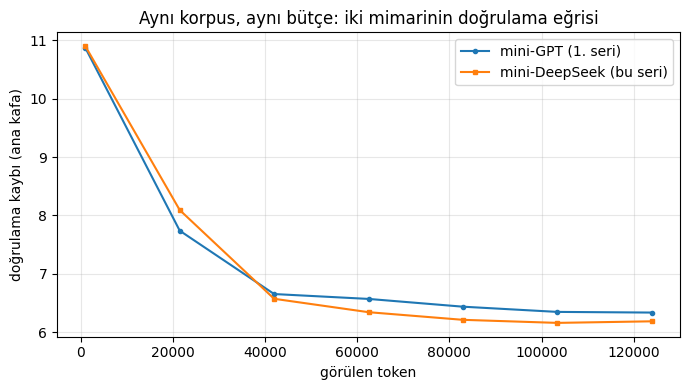

son doğrulama · mini-GPT 6.317 · mini-DeepSeek 6.207


In [57]:
# Düello: aynı bütçe, aynı döngü — Ders 1'in temel koşusuyla aynı Epoch sayısı (15)
torch.manual_seed(123)                                            # aynı tohum: yığın sırası ve Dropout
# mini-GPT'nin AdamW'si: Ders 1'in ayarları
opt = torch.optim.AdamW(gpt_final.parameters(), lr=4e-4, weight_decay=0.1)
_, val_gpt_curve, tok_gpt = train_model(                          # mini-GPT: Ders 1'in döngüsü, tek kayıp
    gpt_final, train_loader, val_loader, opt, device,
    num_epochs=15, eval_freq=20, eval_iter=5, log=False)          # 15 Epoch, her 20 adımda bir ölçüm

torch.manual_seed(123)                                            # aynı tohum
# mini-DeepSeek'in AdamW'si: aynı ayarlar
opt = torch.optim.AdamW(ds_final.parameters(), lr=4e-4, weight_decay=0.1)
_, val_ds_curve, tok_ds = train_model(                            # mini-DeepSeek: aynı döngü
    ds_final, train_loader, val_loader, opt, device,
    num_epochs=15, eval_freq=20, eval_iter=5, log=False,          # aynı 15 Epoch, aynı ölçüm sıklığı
    loss_fn=mtp_loss)                                             # tek fark: kayıp = ana CE + 0.3 × MTP CE

gpt_final.eval(); ds_final.eval()                                 # ölçüm modu: iki modelde Dropout kapalı
with torch.no_grad():                                             # gradyan hesaplanmaz
    final_gpt = calc_loss_loader(val_loader, gpt_final, device)   # karne: mini-GPT'nin doğrulama kaybı
    final_ds = calc_loss_loader(val_loader, ds_final, device)     # karne: mini-DeepSeek, yalnız ana kafa

fig, ax = plt.subplots(figsize=(7, 4))                            # tek grafik
# mini-GPT'nin doğrulama eğrisi: x ekseni görülen token
ax.plot(tok_gpt, val_gpt_curve, label="mini-GPT (1. seri)", marker="o", ms=3)
# mini-DeepSeek'in doğrulama eğrisi (ana kafa)
ax.plot(tok_ds, val_ds_curve, label="mini-DeepSeek (bu seri)", marker="s", ms=3)
# eksen adları
ax.set_xlabel("görülen token"); ax.set_ylabel("doğrulama kaybı (ana kafa)")
# grafiğin başlığı
ax.set_title("Aynı korpus, aynı bütçe: iki mimarinin doğrulama eğrisi")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()   # lejant, ızgara, göster

# iki modelin son doğrulama kaybı yan yana
print(f"son doğrulama · mini-GPT {final_gpt:.3f} · mini-DeepSeek {final_ds:.3f}")

<div class="alert alert-block alert-info">

Kayıtta iki eğri de iniyor ve bir kez yer değiştiriyor: başta mini-DeepSeek üstte, üçüncü ölçümden (~42 bin token) sonra altta; son doğrulama 6.207 ↔ 6.317. Tek tohum ve oyuncak boyda farkın hangi parçadan geldiğini bu deney ayrıştırmıyor — serideki en büyük tek adım Ders 6'daydı: tablolu konumdan RoPE'ye geçiş.

</div>

#### Verimlilik karnesi

<div class="alert alert-block alert-success">

Karne Loss kolonunun yanına iki verimlilik kolonu koyar: token başına cache baytı ve aktif parametre. Loss yalnız ana kafadan (Ders 10'un karne kuralı); hücrenin sonunda mini-DeepSeek `Words are` ile başlayıp 25 token üretir.

</div>

In [58]:
# Verimlilik karnesi: kayıp kolonu ve iki komşusu (cache, aktif parametre)
L, H, hd = GPT_MINI["n_layers"], GPT_MINI["n_heads"], 64           # 4 katman · 4 kafa · kafa boyu 64
cache_gpt = 2 * L * H * hd * 2                                     # mini-GPT: (K + V) × L × H × hd, fp16
cache_ds = L * (DSMOE_CFG["d_latent"] + DSMOE_CFG["d_rope"]) * 2   # mini-DeepSeek: (c + RoPE kanalı) × L

# tablo başlığı: kayıp düellodan, cache mimariden, aktif parametre tartıdan
print(f"{'':<16} {'doğrulama':>10} {'cache bayt/token':>18} {'aktif param':>14}")
# mini-GPT satırı: dense, aktif parametre = toplam
print(f"{'mini-GPT':<16} {final_gpt:>10.3f} {cache_gpt:>18,} {p_gpt:>14,}")
# mini-DeepSeek satırı: aktif parametre, seçilmeyen uzmanlar düşülmüş
print(f"{'mini-DeepSeek':<16} {final_ds:>10.3f} {cache_ds:>18,} {p_ds_active:>14,}")
print(f"\ncache oranı: {cache_gpt / cache_ds:.1f}x küçük · "       # oran ve 128k token'lık bağlamda cache
      f"128k token'lık bağlamda: {fmt_bytes(cache_gpt * 128_000)} yerine {fmt_bytes(cache_ds * 128_000)}")

# Ve final: mini-DeepSeek konuşuyor
# argmax: "Words are" istemine 25 yeni token
out_ids = generate(ds_final, text_to_token_ids("Words are", tokenizer).to(device),
                   max_new_tokens=25, context_size=DSMOE_CFG["context_length"])
print("\nmini-DeepSeek:", token_ids_to_text(out_ids, tokenizer))   # ID'ler -> metin

                  doğrulama   cache bayt/token    aktif param
mini-GPT              6.317              4,096     28,953,600
mini-DeepSeek         6.207                384     28,846,848

cache oranı: 10.7x küçük · 128k token'lık bağlamda: 500.0 MB yerine 46.9 MB



mini-DeepSeek: Words are the


























<div class="alert alert-block alert-info">

Cache kolonu mimarinin formülü (4 096 ↔ 384 bayt/token, 10.7x), sıradaki hücre aynı sayıyı dolu cache'ten sayar; Loss kolonu düellodan, aktif kolonu tartıdan geliyor. Son satırda mini-DeepSeek `the`'den sonra yalnız satır sonu üretiyor: argmax bu boyda tekrar döngüsüne kolay düşer — 23 bin karakterlik korpusta 15 Epoch eğitilmiş ~32 milyon parametrelik modelden anlamlı metin beklenmez.

</div>

#### Cache'li üretim: karnedeki cache gerçek tensörde

<div class="alert alert-block alert-success">

Karnenin cache kolonu formüldü; burada final model gerçekten cache'le üretir. `MiniDeepSeekV3KV` Ders 2'nin kalıbıyla (◆) blok başına `(c, k_rope)` cache'ini ve konum sayacını taşır, düellonun ağırlıklarını yükler; `cache_numbers` dolu cache'teki sayıyı token başına sayar.

</div>

In [59]:
class TransformerBlockV3MoEKV(TransformerBlockV3MoE):
    """Gövdenin bloğu, cache'li: Ders 2'nin TransformerBlockKV'si gibi cache girer, güncel cache çıkar."""

    def forward(self, x, cache, pos_offset):                   # ◆ DEĞİŞTİ: cache + x'in ilk konumu girer
        # ◆ DEĞİŞTİ: cache atılmaz — DecoupledMLA'nın cache dalı (Ders 6): (c, k_rope) girer, güncellenir
        att_out, cache = self.att(self.norm1(x), cache, pos_offset)
        x = x + self.drop_shortcut(att_out)                    # kısayola ekle
        # ◆ DEĞİŞTİ: güncel cache de döner
        return x + self.drop_shortcut(self.ff(self.norm2(x))), cache


class MiniDeepSeekV3KV(MiniDeepSeekV3):
    """Final modelin cache'li hâli: Ders 2'nin GPTModelKV'si gibi blok başına cache + konum sayacı."""

    def __init__(self, cfg):
        super().__init__(cfg, block=TransformerBlockV3MoEKV)   # ◆ DEĞİŞTİ: cache'li bloklar; adlar aynı

    def forward(self, in_idx, caches, pos_offset):             # ◆ DEĞİŞTİ: blok başına cache + konum sayacı
        x = self.drop_emb(self.tok_emb(in_idx))                # konum eklenmez: RoPE, pos_offset'ten döner
        for i, block in enumerate(self.trf_blocks):            # bloklar tek tek, cache'leriyle
            x, caches[i] = block(x, caches[i], pos_offset)     # i. bloğun cache'i yerinde güncellenir
        return self.out_head(self.final_norm(x))               # yalnız ana kafa: MTP üretimde çalışmaz


def cache_numbers(model, ids):
    """Prefill'den sonra GERÇEK cache tensörlerindeki sayı, token başına (bütün katmanlar)."""
    caches = [None] * len(model.trf_blocks)                    # blok başına boş cache
    with torch.no_grad():                                      # gradyan gerekmez
        model(ids, caches=caches, pos_offset=0)                # prefill: dizinin tamamı, cache dolar
    # blok başına (K, V) ya da (c, k_rope): bütün eleman sayısı ÷ token sayısı
    return sum(t.numel() for cache in caches for t in cache) // ids.shape[1]


ds_kv = MiniDeepSeekV3KV(DSMOE_CFG).to(device)                 # aynı ayarlar, cache'li sınıflar
ds_kv.load_state_dict(ds_final.state_dict())                   # düellonun eğitilmiş ağırlıkları, ada göre
ds_kv.eval()                                                   # ölçüm modu: Dropout kapalı, bias donuk
# cache'li yol: karne hücresinin istemi ve 25 token, argmax (Ders 2'nin generate_kv'si)
out_kv = generate_kv(ds_kv, text_to_token_ids("Words are", tokenizer).to(device),
                     max_new_tokens=25, context_size=DSMOE_CFG["context_length"])
# out_ids: karne hücresinde cache'siz generate'in ürettiği token'lar
print("cache'siz ile aynı token'lar mı? ->", bool(torch.equal(out_ids, out_kv)))

# gerçek cache: Ders 2'nin cache'li mini-GPT'si (model_kv) ve final model, aynı dizide
n_gpt, n_ds = cache_numbers(model_kv, out_kv), cache_numbers(ds_kv, out_kv)
print(f"token başına gerçek cache · mini-GPT {n_gpt:,} sayı = {2 * n_gpt:,} bayt (fp16) · "
      f"mini-DeepSeek {n_ds:,} sayı = {2 * n_ds:,} bayt (fp16) · {n_gpt / n_ds:.1f}x küçük")

cache'siz ile aynı token'lar mı? -> True
token başına gerçek cache · mini-GPT 2,048 sayı = 4,096 bayt (fp16) · mini-DeepSeek 192 sayı = 384 bayt (fp16) · 10.7x küçük


<div class="alert alert-block alert-info">

İlk satır `True` olmalı: cache'li yol, karne hücresinin cache'siz ürettiği token'ların aynısını üretir; `False` çıksaydı RoPE'nin konum sayacı (`pos_offset`) ya da maske kaymış olurdu. İkinci satır karnenin cache kolonunu formülden değil dolu cache tensörlerinden okur: 2 048 ↔ 192 sayı, fp16'da 4 096 ↔ 384 bayt.

</div>

### Seri biter: raporun haritası, R1'in yeri

<div class="alert alert-block alert-success">

Bu konunun kodu yok: harita ve köprü anlatım haritasında, aşağıdaki iki kutu onun özetidir.

</div>

#### V3 raporunun haritası

<div class="alert alert-block alert-success">

V3 teknik raporunun mimari bölümü ve FP8 eğitimi bu seride kodlandı: §2.1.1 MLA (Ders 2–4, 6), §2.1.2 DeepSeekMoE (Ders 7–9), §2.2 MTP (Ders 10), §3.3 FP8 (Ders 11). RoPE'nin kendisi RoFormer'dan, ayrık hâli DeepSeek-V2'nin §2.1.3'ünden gelir; DualPipe ve Expert Parallelism çoklu GPU istediği için bilerek dışarıda.

</div>

#### Sırada: Sıfırdan R1

<div class="alert alert-block alert-success">

R1 yeni bir mimari değildir: aynı V3 gövdesi, hiçbir yuvası değişmeden akıl yürütmeye eğitilir. Seri burada bitiyor; sırada Sıfırdan R1 serisi: aynı gövdeye akıl yürütmeyi öğreten tarif.

</div>

<div align="right"><a href="#icindekiler">↑</a> <a href="vscode-notebook-cell:?execution_count=2&line=57">içindekilere dön</a></div>